# Vérification d'une explication orale avec Gemma 4 E4B — une seule inférence


| | Qwen2.5-Omni-7B | Gemma 4 E4B |
|---|---|---|
| Requêtes | 1 | **1** |
| Tokens par page | 640 à 1 280 (1 token = 28 x 28 px) | 560 (1 token = 48 x 48 px) |
| Audio | 25 tokens/s, 300 s par élément | 25 tokens/s, **30 s par élément** → découpé, tous les morceaux dans la même requête |
| Précision sur T4 | float16 | bfloat16 (format d'origine) |

| Sections | Contenu |
|---|---|
| 1 – 5 | paramètres, GPU, installation, imports, outil de mesure (le même que dans les autres notebooks) |
| 6 – 9 | chargement du modèle, PDF, pages, audio |
| 10 – 12 | requête unique, entrées du modèle, génération |
| 13 – 14 | extraction des erreurs, rapport |
| 15 – 16 | évaluation des performances, comparaison avec Qwen ou Phi-4 |

In [9]:
CHEMIN_PDF = "/kaggle/input/datasets/eyajall/communication/Chapitre_4_Parties_Prenantes_Communication_Risques.pdf"
CHEMIN_AUDIO = "/kaggle/input/datasets/eyajall/communication/Voix_261123_202702.mp3"

# --- Modèle ---
MODEL_ID = "google/gemma-4-E4B-it"   # licence Apache 2.0 : gratuit, sans demande d'accès
PRECISION = "bfloat16"         # "bfloat16" : format d'origine du modèle (comme l'exemple officiel de Google sur T4)
                               # "float16"  : plus rapide sur T4, mais risque de NaN → repli automatique en bfloat16
RESERVE_ACTIVATIONS_GIO = 3.0  # mémoire laissée libre sur chaque GPU pour les calculs (activations, cache)

# --- Pages du PDF ---
PAGES_A_ANALYSER = "14-20"     # slides dont parle l'audio ; None = toutes les pages
TOKENS_PAR_PAGE = 560          # budget visuel de Gemma 4 par image : 70, 140, 280, 560 ou 1120
                               # 560 ≈ 1 500 x 850 px pour une diapositive 16:9 (texte lisible) ; 1120 = plus net mais 2x plus de tokens
AJOUTER_TEXTE_PDF = True       # ajoute sous chaque image le texte de la page extrait du PDF
MAX_CARACTERES_TEXTE_PAGE = 3000

# --- Audio ---
NORMALISER_VOLUME = True       # remonte le volume de la version envoyée au modèle (crête à 0,9) ; l'original n'est jamais modifié
DUREE_MAX_SEGMENT_S = 30       # LIMITE de Gemma 4 : 30 s par élément audio (au-delà, le processor coupe sans prévenir).
                               # L'audio est donc découpé en morceaux de 30 s maximum, TOUS envoyés dans la même requête.

# --- Génération du rapport ---
MAX_NOUVEAUX_TOKENS = 2048     # écoute + vérification de chaque affirmation (~150 tokens par affirmation)
ECHANTILLONNAGE = False        # False = réponse déterministe (recommandé pour une évaluation)
AFFICHER_EN_DIRECT = True

# --- Évaluation des performances ---
TRANSCRIPTION_REFERENCE = None  # facultatif : ce que tu as réellement dit (texte) → taux d'erreur de mots de l'écoute (WER)
INTERVALLE_MESURE_S = 0.5

# --- Comparaison (section 16) ---
DOSSIER_RESULTATS_AUTRE_MODELE = None   # dossier des résultats de Qwen ou de Phi-4 (performance.json…) ; None = recherche automatique

DOSSIER_ENTREES = "/kaggle/input"
DOSSIER_TRAVAIL = "/kaggle/working/analyse_gemma4"

In [10]:
import os, sys, shutil, subprocess, json, time, gc, math, re, hashlib, warnings
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")   # limite la fragmentation mémoire GPU
import torch

# Dossier de sortie (images des pages, audio préparé, résultats)
os.makedirs(DOSSIER_TRAVAIL, exist_ok=True)


def mesurer_memoire_libre(gpus):
    """Met à jour la mémoire libre/totale (en Gio) de chaque GPU de la liste."""
    for g in gpus:
        libre, total = torch.cuda.mem_get_info(g["index"])
        g["libre_gio"], g["total_gio"] = libre / 2**30, total / 2**30
    return gpus


def liberer_memoire():
    """Libère la mémoire GPU inutilisée (après une erreur ou avant un rechargement)."""
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()


def est_erreur_memoire(e):
    return isinstance(e, torch.cuda.OutOfMemoryError) or "out of memory" in str(e).lower()


# --- GPU : détection + test de calcul réel en FP16 et en BF16 ---
if not torch.cuda.is_available():
    raise RuntimeError("❌ Aucun GPU CUDA détecté. Settings → Accelerator → 'GPU T4 x2', puis relancez la session.")

GPU_UTILISABLES = []
for i in range(torch.cuda.device_count()):
    prop = torch.cuda.get_device_properties(i)
    try:
        a = torch.randn(512, 512, device=f"cuda:{i}", dtype=torch.float16)
        utilisable = bool(torch.isfinite((a @ a).float().sum()).item())
        del a
    except Exception:
        utilisable = False
    try:   # bfloat16 : natif à partir d'Ampere ; sur T4 (Turing), PyTorch le calcule sans les cœurs Tensor (plus lent)
        b = torch.randn(512, 512, device=f"cuda:{i}", dtype=torch.bfloat16)
        bf16_ok = bool(torch.isfinite((b @ b).float().sum()).item())
        del b
    except Exception:
        bf16_ok = False
    if utilisable:
        GPU_UTILISABLES.append({"index": i, "nom": prop.name, "bf16_natif": prop.major >= 8, "bf16_utilisable": bf16_ok})

if not GPU_UTILISABLES:
    raise RuntimeError("❌ GPU détecté mais inutilisable avec cette version de PyTorch. "
                       "Choisissez 'GPU T4 x2' dans Settings → Accelerator.")

mesurer_memoire_libre(GPU_UTILISABLES)
torch.cuda.empty_cache()
for g in GPU_UTILISABLES:
    print(f"✅ GPU {g['index']} : {g['nom']} | {g['libre_gio']:.1f} / {g['total_gio']:.1f} Gio libres | "
          f"BF16 : {'natif' if g['bf16_natif'] else 'possible sans cœurs Tensor (plus lent)' if g['bf16_utilisable'] else 'indisponible'}")

✅ GPU 0 : Tesla T4 | 14.4 / 14.6 Gio libres | BF16 : possible sans cœurs Tensor (plus lent)
✅ GPU 1 : Tesla T4 | 14.4 / 14.6 Gio libres | BF16 : possible sans cœurs Tensor (plus lent)


## 3) Installation

| Paquet | Rôle |
|---|---|
| `transformers` 5.24.0 | Gemma 4 (`Gemma4ForConditionalGeneration`, `Gemma4Processor`) |
| `accelerate` | répartition du modèle sur les 2 GPU |
| `pymupdf` | lecture du PDF : texte et images des pages |
| `soundfile`, `librosa` | lecture de l'audio, passage en 16 kHz |
| `pandas`, `psutil`, `nvidia-ml-py`, `matplotlib` | mesures des performances et graphiques |

In [11]:
import importlib.metadata as metadata

VERSIONS = {
    "transformers": "5.24.0",   # contient Gemma4ForConditionalGeneration (même version que les notebooks Qwen et Phi-4)
    "accelerate": "1.16.0"
    "pymupdf": "2.1",
    "soundfile": "0.14.0",
}


def pip_installer(paquets, options=()):
    """Installe des paquets avec pip dans l'environnement du notebook."""
    commande = [sys.executable, "-m", "pip", "install", "-q", "--disable-pip-version-check", *options, *paquets]
    print("pip install", " ".join(list(options) + list(paquets)))
    res = subprocess.run(commande, capture_output=True, text=True)
    if res.returncode != 0:
        print(res.stdout[-2000:], res.stderr[-3000:])
        raise RuntimeError("❌ Échec de l'installation (vérifiez que Internet est activé : Settings → Internet → On).")


def fichiers_presents(dossier, extensions):
    if not os.path.isdir(dossier):
        return []
    return sorted(os.path.join(r, f) for r, _, fs in os.walk(dossier) for f in fs if f.lower().endswith(extensions))


if "transformers" in sys.modules and sys.modules["transformers"].__version__ != VERSIONS["transformers"]:
    print("⚠️  Une autre version de transformers est déjà importée dans cette session : "
          "après l'installation, faites Run → Restart & clear cell outputs, puis relancez tout.")

PERF_INSTALLATION_T0 = time.time()
paquets = [f"{nom}=={version}" for nom, version in VERSIONS.items()]
paquets += ["librosa", "pillow", "matplotlib"]           # rééchantillonnage audio en 16 kHz ; aperçu des pages
paquets += ["pandas", "psutil", "nvidia-ml-py"]          # évaluation des performances : tableaux, CPU/RAM, GPU
pip_installer(paquets)

DUREE_INSTALLATION_S = time.time() - PERF_INSTALLATION_T0
print(f"\nInstallation terminée en {DUREE_INSTALLATION_S:.0f} s. Versions installées :")
for nom in list(VERSIONS) + ["librosa", "pillow", "matplotlib", "pandas", "psutil", "nvidia-ml-py", "torch", "torchvision"]:
    try:
        print(f"   {nom:16s} {metadata.version(nom)}")
    except metadata.PackageNotFoundError:
        print(f"   {nom:16s} ❌ absent")
for nom, version in VERSIONS.items():
    assert metadata.version(nom) == version, f"{nom} {metadata.version(nom)} installé au lieu de {version}"
print("✅ Dépendances prêtes (aucun outil de transcription : pas de Whisper).")

pip install transformers==5.24.0 accelerate==1.16.0 pymupdf==2.1 soundfile==0.14.0 librosa pillow matplotlib pandas psutil nvidia-ml-py

Installation terminée en 3 s. Versions installées :
   transformers     5.24.0
   accelerate       1.16.0
   pymupdf          2.1
   soundfile        0.14.0
   librosa          0.11.0
   pillow           13.0.0
   matplotlib       3.10.0
   pandas           2.3.3
   psutil           5.9.5
   nvidia-ml-py     13.615.71
   torch            2.11.0+cu130
   torchvision      0.26.0+cu130
✅ Dépendances prêtes (aucun outil de transcription : pas de Whisper).


## 4. Imports

In [12]:
import threading
import unicodedata
import inspect
from collections import Counter
from datetime import datetime
import numpy as np
import pandas as pd
import psutil
import pymupdf                      # PyMuPDF (ancien nom d'import : fitz)
from PIL import Image
import soundfile as sf
import librosa
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Audio as LecteurAudio

import transformers, accelerate
from transformers import (
    AutoConfig,
    AutoProcessor,                      # Gemma4Processor : tokenizer + images + audio
    Gemma4ForConditionalGeneration,     # Gemma 4 : encodeur vision + encodeur audio + modèle de langage (sortie texte)
    TextStreamer,
    LogitsProcessor,
    LogitsProcessorList,
)
from transformers.models.gemma4.image_processing_gemma4 import get_aspect_ratio_preserving_size
from accelerate import init_empty_weights
from huggingface_hub import snapshot_download

transformers.logging.set_verbosity_error()
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="librosa")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

# Jeton Hugging Face facultatif (Kaggle → Add-ons → Secrets → HF_TOKEN) : non requis, le modèle est public
try:
    from kaggle_secrets import UserSecretsClient
    os.environ.setdefault("HF_TOKEN", UserSecretsClient().get_secret("HF_TOKEN"))
    print("Jeton Hugging Face chargé depuis les secrets Kaggle.")
except Exception:
    pass

print(f"torch {torch.__version__} | transformers {transformers.__version__} | accelerate {accelerate.__version__} | "
      f"PyMuPDF {pymupdf.VersionBind} | soundfile {sf.__version__} | librosa {librosa.__version__} | "
      f"numpy {np.__version__} | pandas {pd.__version__}")
assert transformers.__version__ == VERSIONS["transformers"], (
    f"transformers {transformers.__version__} est chargé au lieu de {VERSIONS['transformers']} : "
    "redémarrez la session (Run → Restart) puis relancez le notebook.")
print("MP3 pris en charge par soundfile :", "MP3" in sf.available_formats())
print("✅ Bibliothèques importées : Gemma4ForConditionalGeneration, AutoProcessor")

torch 2.11.0+cu130 | transformers 5.24.0 | accelerate 1.16.0 | PyMuPDF 2.1 | soundfile 0.14.0 | librosa 0.11.0 | numpy 2.1.3 | pandas 2.3.3
MP3 pris en charge par soundfile : True
✅ Bibliothèques importées : Gemma4ForConditionalGeneration, AutoProcessor


## 5. Outil de mesure des performances

Le **même outil que dans les notebooks Qwen et Phi-4** : chiffres directement comparables. Un fil d'exécution relève en
continu l'utilisation, la mémoire et la puissance de chaque GPU, ainsi que le CPU et la RAM. Chaque étape est encadrée par
`PERF.debut("…")` / `PERF.fin()` et l'appel au modèle est mesuré (lecture de l'entrée, écriture, tokens, énergie).

In [13]:
# Un fil d'exécution (thread) relève en continu, toutes les INTERVALLE_MESURE_S secondes :
#   - pour chaque GPU : utilisation (%), mémoire occupée, puissance électrique (W)
#   - pour le notebook : RAM utilisée et CPU
# Chaque étape (PERF.debut / PERF.fin) et chaque appel au modèle (inférence) est une fenêtre de temps dans ces
# relevés : on en déduit sa durée, ses pics, ses moyennes et l'énergie consommée par les GPU.
try:
    import pynvml                 # fourni par le paquet nvidia-ml-py
    pynvml.nvmlInit()
    NVML_DISPONIBLE = True
except Exception as e:
    NVML_DISPONIBLE = False
    print(f"ℹ️  NVML indisponible ({type(e).__name__}) : les mesures GPU passent par nvidia-smi (une par seconde).")

COULEURS_GPU = ["#2a78d6", "#eb6834"]           # GPU 0 = bleu, GPU 1 = orange (toujours la même couleur par GPU)
ENCRE, ENCRE_SECONDAIRE, GRILLE = "#0b0b0b", "#52514e", "#e4e3df"


def duree_lisible(secondes):
    secondes = float(secondes)
    if secondes < 60:
        return f"{secondes:.1f} s"
    minutes, s = divmod(secondes, 60)
    if minutes < 60:
        return f"{int(minutes)} min {s:02.0f} s"
    heures, minutes = divmod(minutes, 60)
    return f"{int(heures)} h {int(minutes):02d} min"


def _moyenne(valeurs):
    v = np.asarray(valeurs, dtype=float)
    v = v[np.isfinite(v)]
    return float(v.mean()) if v.size else float("nan")


def _maximum(valeurs):
    v = np.asarray(valeurs, dtype=float)
    v = v[np.isfinite(v)]
    return float(v.max()) if v.size else float("nan")


class Mesureur:
    """Mesure du temps et des ressources (GPU, CPU, RAM, énergie) de chaque étape et de chaque inférence."""

    def __init__(self, intervalle_s=0.5):
        self.intervalle = intervalle_s if NVML_DISPONIBLE else max(intervalle_s, 1.0)
        self.n_gpu = torch.cuda.device_count()
        self.processus = psutil.Process(os.getpid())
        self.processus.cpu_percent(None)
        self.poignees = self._poignees_gpu()
        self.t_origine = time.perf_counter()
        self.releves = []          # (t, RAM du notebook en Mo, CPU en %, [(utilisation %, mémoire Mo, puissance W) par GPU])
        self.etapes, self.inferences = [], []
        self._etape = None
        self._pics_etape = [0] * self.n_gpu
        self._verrou = threading.Lock()
        self._arret = threading.Event()
        self._fil = threading.Thread(target=self._boucle, daemon=True)
        self._fil.start()

    # ---------- relevés ----------
    def _poignees_gpu(self):
        if not NVML_DISPONIBLE:
            return [None] * self.n_gpu
        poignees = []
        for i in range(self.n_gpu):
            h = None
            try:   # on retrouve le GPU par son identifiant unique (l'ordre NVML peut différer de l'ordre de PyTorch)
                uuid = str(torch.cuda.get_device_properties(i).uuid)
                h = pynvml.nvmlDeviceGetHandleByUUID(uuid if uuid.startswith("GPU-") else "GPU-" + uuid)
            except Exception:
                try:
                    h = pynvml.nvmlDeviceGetHandleByIndex(i)
                except Exception:
                    h = None
            poignees.append(h)
        return poignees

    def _releve_gpu(self):
        vide = (float("nan"),) * 3
        if NVML_DISPONIBLE:
            resultats = []
            for h in self.poignees:
                try:
                    resultats.append((float(pynvml.nvmlDeviceGetUtilizationRates(h).gpu),
                                      pynvml.nvmlDeviceGetMemoryInfo(h).used / 2**20,
                                      pynvml.nvmlDeviceGetPowerUsage(h) / 1000))
                except Exception:
                    resultats.append(vide)
            return resultats
        try:
            sortie = subprocess.run(["nvidia-smi", "--query-gpu=utilization.gpu,memory.used,power.draw",
                                     "--format=csv,noheader,nounits"], capture_output=True, text=True, timeout=5).stdout
            resultats = []
            for ligne in sortie.strip().splitlines()[: self.n_gpu]:
                valeurs = []
                for v in ligne.split(",")[:3]:
                    try:
                        valeurs.append(float(v))
                    except ValueError:
                        valeurs.append(float("nan"))
                resultats.append(tuple(valeurs + [float("nan")] * (3 - len(valeurs))))
            return resultats + [vide] * (self.n_gpu - len(resultats))
        except Exception:
            return [vide] * self.n_gpu

    def releve(self):
        r = (time.perf_counter(), self.processus.memory_info().rss / 2**20, self.processus.cpu_percent(None), self._releve_gpu())
        with self._verrou:
            self.releves.append(r)
        return r

    def _boucle(self):
        while not self._arret.wait(self.intervalle):
            try:
                self.releve()
            except Exception:
                pass

    def arreter(self):
        self._arret.set()

    def _resume(self, t0, t1):
        """Statistiques des relevés pris entre t0 et t1."""
        with self._verrou:
            r = [x for x in self.releves if t0 <= x[0] <= t1]
        res = {"ram_pic_mo": _maximum([x[1] for x in r]), "cpu_moyen_pct": _moyenne([x[2] for x in r])}
        energie_totale = 0.0
        for i in range(self.n_gpu):
            util = [x[3][i][0] for x in r]
            memoire = [x[3][i][1] for x in r]
            puissance = [x[3][i][2] for x in r]
            res[f"gpu{i}_util_moy_pct"] = _moyenne(util)
            res[f"gpu{i}_util_max_pct"] = _maximum(util)
            res[f"gpu{i}_occupe_pic_mo"] = _maximum(memoire)            # mémoire occupée vue par le pilote (tout compris)
            res[f"gpu{i}_puissance_moy_w"] = _moyenne(puissance)
            energie = res[f"gpu{i}_puissance_moy_w"] * (t1 - t0) / 3600     # Wh = puissance moyenne x durée
            res[f"gpu{i}_energie_wh"] = energie
            energie_totale += energie if np.isfinite(energie) else 0.0
        res["energie_gpu_wh"] = energie_totale
        return res

    # ---------- pics de mémoire PyTorch ----------
    def _replier_pics(self):
        for i in range(self.n_gpu):
            self._pics_etape[i] = max(self._pics_etape[i], torch.cuda.max_memory_allocated(i))

    def _remise_a_zero_pics(self):
        for i in range(self.n_gpu):
            torch.cuda.reset_peak_memory_stats(i)

    # ---------- étapes du notebook ----------
    def debut(self, nom):
        if self._etape is not None:
            self.fin()
        self._pics_etape = [0] * self.n_gpu
        self._remise_a_zero_pics()
        self.releve()
        self._etape = {"etape": nom, "t_debut": time.perf_counter(), "_cpu_debut": sum(self.processus.cpu_times()[:2])}

    def fin(self, afficher=True, **details):
        e, self._etape = self._etape, None
        if e is None:
            return None
        self.releve()
        e["t_fin"] = time.perf_counter()
        e["duree_s"] = e["t_fin"] - e["t_debut"]
        e["temps_cpu_s"] = sum(self.processus.cpu_times()[:2]) - e.pop("_cpu_debut")
        self._replier_pics()
        for i in range(self.n_gpu):
            e[f"gpu{i}_pic_pytorch_mo"] = self._pics_etape[i] / 2**20
        e.update(self._resume(e["t_debut"], e["t_fin"]))
        e.update(details)
        self.etapes = [x for x in self.etapes if x["etape"] != e["etape"]] + [e]   # cellule relancée : on remplace
        if afficher:
            print(f"⏱️  {e['etape']} : {duree_lisible(e['duree_s'])}"
                  + (f" | énergie GPU ≈ {e['energie_gpu_wh']:.2f} Wh" if e["energie_gpu_wh"] > 0 else ""))
        return e

    def ajouter(self, nom, duree_s, **details):
        """Étape mesurée en dehors de l'outil (ex. installation, faite avant sa création)."""
        e = {"etape": nom, "t_debut": float("nan"), "t_fin": float("nan"), "duree_s": float(duree_s), **details}
        self.etapes = [x for x in self.etapes if x["etape"] != nom] + [e]

    # ---------- inférences (appels à model.generate) ----------
    def debut_inference(self, nom, **infos):
        self._replier_pics()
        self._remise_a_zero_pics()
        self.releve()
        return {"inference": nom, **infos, "t_debut": time.perf_counter()}

    def fin_inference(self, rec, t_premier_token, n_tokens_sortie):
        rec["t_fin"] = time.perf_counter()
        self.releve()
        rec["duree_s"] = rec["t_fin"] - rec["t_debut"]
        rec["tokens_sortie"] = int(n_tokens_sortie)
        # Temps jusqu'au premier token = le modèle « lit » toute l'entrée (images, audio, texte) : phase de pré-remplissage
        rec["ttft_s"] = (t_premier_token - rec["t_debut"]) if t_premier_token else float("nan")
        ecriture = (rec["t_fin"] - t_premier_token) if t_premier_token else float("nan")
        rec["ecriture_s"] = ecriture
        rec["vitesse_lecture_tok_s"] = rec["tokens_entree"] / rec["ttft_s"] if rec["ttft_s"] > 0 else float("nan")
        rec["vitesse_ecriture_tok_s"] = ((n_tokens_sortie - 1) / ecriture
                                         if n_tokens_sortie > 1 and ecriture > 0 else float("nan"))
        for i in range(self.n_gpu):
            rec[f"gpu{i}_pic_pytorch_mo"] = torch.cuda.max_memory_allocated(i) / 2**20
        self._replier_pics()
        rec.update(self._resume(rec["t_debut"], rec["t_fin"]))
        self.inferences = [x for x in self.inferences if x["inference"] != rec["inference"]] + [rec]
        return rec

    # ---------- tableaux ----------
    def _par_gpu(self, d, cle, diviseur=1.0, decimales=1):
        valeurs = []
        for i in range(self.n_gpu):
            v = d.get(f"gpu{i}{cle}", float("nan"))
            valeurs.append("—" if not np.isfinite(v) else f"{v / diviseur:.{decimales}f}")
        return " / ".join(valeurs)

    def tableau_etapes(self):
        total = sum(e["duree_s"] for e in self.etapes) or 1.0
        lignes = []
        for e in self.etapes:
            lignes.append({
                "Étape": e["etape"],
                "Durée": duree_lisible(e["duree_s"]),
                "% du temps": f"{100 * e['duree_s'] / total:.0f} %",
                "Temps CPU (s)": f"{e['temps_cpu_s']:.0f}" if np.isfinite(e.get("temps_cpu_s", float("nan"))) else "—",
                "RAM pic (Gio)": f"{e['ram_pic_mo'] / 1024:.1f}" if np.isfinite(e.get("ram_pic_mo", float("nan"))) else "—",
                "Mémoire PyTorch pic (Gio) GPU0 / GPU1": self._par_gpu(e, "_pic_pytorch_mo", 1024, 2),
                "Utilisation GPU moy. (%) GPU0 / GPU1": self._par_gpu(e, "_util_moy_pct", 1, 0),
                "Énergie GPU (Wh)": f"{e['energie_gpu_wh']:.2f}" if e.get("energie_gpu_wh") else "—",
            })
        return pd.DataFrame(lignes)

    def tableau_inferences(self):
        lignes = []
        for r in self.inferences:
            lignes.append({
                "Inférence": r["inference"],
                "Adaptateur": r.get("adaptateur", ""),
                "Tokens entrée (image / audio / texte)": f"{r['tokens_entree']} ({r.get('tokens_image', 0)} / "
                                                         f"{r.get('tokens_audio', 0)} / {r.get('tokens_texte', 0)})",
                "Tokens sortie": r["tokens_sortie"],
                "Durée (s)": f"{r['duree_s']:.1f}",
                "Lecture de l'entrée (s)": f"{r['ttft_s']:.1f}",
                "Écriture (tokens/s)": f"{r['vitesse_ecriture_tok_s']:.1f}" if np.isfinite(r["vitesse_ecriture_tok_s"]) else "—",
                "Mémoire PyTorch pic (Gio) GPU0 / GPU1": self._par_gpu(r, "_pic_pytorch_mo", 1024, 2),
                "Utilisation GPU moy. (%) GPU0 / GPU1": self._par_gpu(r, "_util_moy_pct", 1, 0),
                "Puissance moy. (W) GPU0 / GPU1": self._par_gpu(r, "_puissance_moy_w", 1, 0),
                "Énergie GPU (Wh)": f"{r['energie_gpu_wh']:.3f}",
            })
        return pd.DataFrame(lignes)

    # ---------- graphiques ----------
    @staticmethod
    def _style(ax):
        for cote in ("top", "right"):
            ax.spines[cote].set_visible(False)
        for cote in ("left", "bottom"):
            ax.spines[cote].set_color(GRILLE)
        ax.tick_params(colors=ENCRE_SECONDAIRE, labelsize=9)
        ax.grid(axis="x", color=GRILLE, linewidth=0.8)
        ax.set_axisbelow(True)

    def graphique_etapes(self):
        etapes = [e for e in self.etapes if e["duree_s"] > 0]
        if not etapes:
            return
        fig, ax = plt.subplots(figsize=(10, 0.45 * len(etapes) + 1.2))
        noms = [e["etape"] for e in etapes][::-1]
        durees = [e["duree_s"] for e in etapes][::-1]
        barres = ax.barh(noms, durees, color=COULEURS_GPU[0], height=0.6)
        for b, d in zip(barres, durees):
            ax.text(b.get_width(), b.get_y() + b.get_height() / 2, "  " + duree_lisible(d), va="center",
                    fontsize=9, color=ENCRE)
        ax.set_xlabel("Durée (s)", color=ENCRE_SECONDAIRE)
        ax.set_title("Temps passé dans chaque étape", loc="left", color=ENCRE, fontsize=12)
        ax.set_xlim(0, max(durees) * 1.25)
        self._style(ax)
        ax.tick_params(axis="y", colors=ENCRE, labelsize=9)
        plt.tight_layout()
        plt.show()

    def graphique_inferences(self):
        if not self.inferences:
            return
        noms = [r["inference"] for r in self.inferences][::-1]
        lecture = [r["ttft_s"] if np.isfinite(r["ttft_s"]) else 0 for r in self.inferences][::-1]
        ecriture = [r["ecriture_s"] if np.isfinite(r["ecriture_s"]) else r["duree_s"] for r in self.inferences][::-1]
        hauteur = 0.45 * len(noms) + 2.0
        fig, ax = plt.subplots(figsize=(10, hauteur))
        ax.barh(noms, lecture, color=COULEURS_GPU[0], height=0.6, label="lecture de l'entrée (jusqu'au 1er token)",
                edgecolor="white", linewidth=2)
        ax.barh(noms, ecriture, left=lecture, color=COULEURS_GPU[1], height=0.6, label="écriture de la réponse",
                edgecolor="white", linewidth=2)
        for y, (l, e) in enumerate(zip(lecture, ecriture)):
            ax.text(l + e, y, f"  {l + e:.1f} s", va="center", fontsize=9, color=ENCRE)
        ax.set_xlabel("Durée (s)", color=ENCRE_SECONDAIRE)
        ax.set_title("Durée de chaque appel au modèle", loc="left", color=ENCRE, fontsize=12)
        ax.set_xlim(0, max(l + e for l, e in zip(lecture, ecriture)) * 1.2)
        fig.legend(loc="lower left", bbox_to_anchor=(0.01, 0.01), ncol=2, frameon=False, fontsize=9)   # sous le graphique
        self._style(ax)
        ax.tick_params(axis="y", colors=ENCRE, labelsize=9)
        plt.tight_layout(rect=(0, 0.4 / hauteur, 1, 1))
        plt.show()

    def graphique_chronologie(self):
        """Mémoire, utilisation et puissance des GPU au fil du temps (un graphique par mesure, même axe du temps)."""
        with self._verrou:
            r = list(self.releves)
        if len(r) < 2 or self.n_gpu == 0:
            return
        t = (np.array([x[0] for x in r]) - self.t_origine) / 60
        mesures = [("Mémoire occupée (Gio)", 1, 1 / 1024), ("Utilisation (%)", 0, 1), ("Puissance (W)", 2, 1)]
        fig, axes = plt.subplots(len(mesures), 1, figsize=(11, 7.5), sharex=True)
        for ax, (titre, k, facteur) in zip(axes, mesures):
            for i in range(self.n_gpu):
                y = np.array([x[3][i][k] for x in r], dtype=float) * facteur
                ax.plot(t, y, color=COULEURS_GPU[i % len(COULEURS_GPU)], linewidth=2, label=f"GPU {i}")
            for rec in self.inferences:                 # zones grisées = appels au modèle
                ax.axvspan((rec["t_debut"] - self.t_origine) / 60, (rec["t_fin"] - self.t_origine) / 60,
                           color=GRILLE, alpha=0.6, linewidth=0)
            ax.set_title(titre, loc="left", color=ENCRE, fontsize=11)
            ax.set_ylim(bottom=0)
            self._style(ax)
            ax.grid(axis="y", color=GRILLE, linewidth=0.8)
        axes[0].legend(loc="upper left", frameon=False, fontsize=9, ncol=self.n_gpu)
        axes[-1].set_xlabel("Temps depuis le début des mesures (min) — zones grisées : appels au modèle",
                            color=ENCRE_SECONDAIRE)
        plt.tight_layout()
        plt.show()

    # ---------- sauvegarde ----------
    def sauvegarder(self, dossier, resume=None):
        os.makedirs(dossier, exist_ok=True)
        sans_temps = lambda d: {k: v for k, v in d.items() if not k.startswith("t_")}
        pd.DataFrame([sans_temps(e) for e in self.etapes]).to_csv(os.path.join(dossier, "performance_etapes.csv"), index=False)
        pd.DataFrame([sans_temps(r) for r in self.inferences]).to_csv(os.path.join(dossier, "performance_inferences.csv"),
                                                                      index=False)
        propre = lambda v: None if isinstance(v, float) and not np.isfinite(v) else v
        donnees = {"resume": {k: propre(v) for k, v in (resume or {}).items()},
                   "etapes": [{k: propre(v) for k, v in sans_temps(e).items()} for e in self.etapes],
                   "inferences": [{k: propre(v) for k, v in sans_temps(r).items()} for r in self.inferences]}
        with open(os.path.join(dossier, "performance.json"), "w", encoding="utf-8") as f:
            json.dump(donnees, f, ensure_ascii=False, indent=2, default=str)


if "PERF" in globals():          # cellule relancée : on arrête l'ancien fil de mesure
    PERF.arreter()
PERF = Mesureur(INTERVALLE_MESURE_S)
if "DUREE_INSTALLATION_S" in globals():      # absente si la cellule d'installation n'a pas été relancée
    PERF.ajouter("Installation des bibliothèques", DUREE_INSTALLATION_S)
print(f"✅ Mesures démarrées : un relevé toutes les {PERF.intervalle:.1f} s "
      f"({'NVML' if NVML_DISPONIBLE else 'nvidia-smi'}) sur {PERF.n_gpu} GPU + CPU + RAM")
for i in range(PERF.n_gpu):
    _, _, _, gpus = PERF.releve()
    util, memoire, puissance = gpus[i]
    print(f"   GPU {i} ({torch.cuda.get_device_properties(i).name}) : {memoire / 1024:.1f} Gio occupés, "
          f"utilisation {util:.0f} %, puissance {puissance:.0f} W")
print(f"   RAM du notebook : {PERF.processus.memory_info().rss / 2**30:.1f} Gio | "
      f"{psutil.cpu_count()} cœurs CPU | RAM de la machine : {psutil.virtual_memory().total / 2**30:.0f} Gio")

✅ Mesures démarrées : un relevé toutes les 0.5 s (NVML) sur 2 GPU + CPU + RAM
   GPU 0 (Tesla T4) : 0.6 Gio occupés, utilisation 0 %, puissance 30 W
   GPU 1 (Tesla T4) : 0.6 Gio occupés, utilisation 0 %, puissance 32 W
   RAM du notebook : 2.1 Gio | 4 cœurs CPU | RAM de la machine : 31 Gio


##  Chargement d modèle


In [14]:
# Si un modèle est déjà chargé (cellule relancée), on le libère pour mesurer la mémoire réellement disponible
if globals().get("model") is not None:
    print("ℹ️  Un modèle était déjà chargé dans cette session : libération de la mémoire GPU avant rechargement.")
    model = None
    liberer_memoire()

# 6.1 Configuration officielle et taille exacte du modèle (sans télécharger les poids)
try:
    CONFIG = AutoConfig.from_pretrained(MODEL_ID)
except Exception as e:
    raise RuntimeError(f"❌ Impossible de lire la configuration de {MODEL_ID} : Internet est-il activé ? ({e})") from e

with init_empty_weights():   # modèle « vide » : aucune mémoire allouée pour les poids
    _vide = Gemma4ForConditionalGeneration._from_config(CONFIG)
_lm = _vide.model.language_model
compter = lambda *modules: sum(p.numel() for m in modules if m is not None for p in m.parameters())
_tables = compter(_lm.embed_tokens, getattr(_lm, "embed_tokens_per_layer", None))
N_PARAMS = compter(_vide)
N_PARAMS_PAR_BLOC = {
    "encodeur vision": compter(_vide.model.vision_tower, _vide.model.embed_vision),
    "encodeur audio": compter(_vide.model.audio_tower, _vide.model.embed_audio),
    "modèle de langage": compter(_lm) - _tables,
    "tables d'embeddings": _tables,     # simples tables de correspondance (dont une petite table par couche : PLE)
}
del _vide, _lm
TAILLE_16BITS_GIO = N_PARAMS * 2 / 2**30
N_PARAMS_TABLES = N_PARAMS_PAR_BLOC["tables d'embeddings"]
print(f"Gemma 4 E4B : {N_PARAMS / 1e9:.2f} milliards de paramètres "
      f"(dont {N_PARAMS_TABLES / 1e9:.2f} dans des tables d'embeddings, simplement lues)")
for nom, n in N_PARAMS_PAR_BLOC.items():
    print(f"   - {nom:20s}: {n / 1e9:.3f} milliard")
print(f"Mémoire nécessaire pour les poids en 16 bits ≈ {TAILLE_16BITS_GIO:.1f} Gio")

# 6.2 Précision et mémoire disponible
BF16_UTILISABLE = all(g["bf16_utilisable"] for g in GPU_UTILISABLES)
if PRECISION == "bfloat16" and BF16_UTILISABLE:
    DTYPE = torch.bfloat16
elif PRECISION == "bfloat16":
    print("⚠️  bfloat16 indisponible sur ce GPU → float16 (repli automatique si des NaN apparaissent : impossible ici).")
    DTYPE = torch.float16
else:
    DTYPE = torch.float16
mesurer_memoire_libre(GPU_UTILISABLES)
CAPACITES = {g["index"]: max(0.0, g["libre_gio"] - RESERVE_ACTIVATIONS_GIO) for g in GPU_UTILISABLES}
for g in GPU_UTILISABLES:
    print(f"GPU {g['index']} ({g['nom']}) : {g['libre_gio']:.1f} Gio libres sur {g['total_gio']:.1f} Gio")
if TAILLE_16BITS_GIO * 1.03 > sum(CAPACITES.values()):
    raise MemoryError(f"❌ Mémoire GPU insuffisante : {sum(CAPACITES.values()):.1f} Gio utilisables (après "
                      f"{RESERVE_ACTIVATIONS_GIO} Gio de marge par GPU) pour {TAILLE_16BITS_GIO:.1f} Gio de poids. "
                      "Choisissez 'GPU T4 x2' (Settings → Accelerator) ou réduisez RESERVE_ACTIVATIONS_GIO.")
print(f"\n➡️  Chargement en {str(DTYPE).replace('torch.', '')} : poids ≈ {TAILLE_16BITS_GIO:.1f} Gio pour "
      f"{sum(CAPACITES.values()):.1f} Gio utilisables, répartis sur {len(GPU_UTILISABLES)} GPU")

# 6.3 Téléchargement des poids (une seule fois : ensuite le cache est réutilisé)
PERF.debut("Téléchargement du modèle")
t0 = time.time()
try:
    DOSSIER_MODELE = snapshot_download(repo_id=MODEL_ID,
                                       allow_patterns=["*.json", "*.safetensors", "*.jinja", "*.model", "*.txt"])
except Exception as e:
    raise RuntimeError(f"❌ Téléchargement de {MODEL_ID} impossible ({type(e).__name__}: {e}).\n"
                       "   Vérifiez : Settings → Internet → On, et l'espace disque.") from e
poids = [f for f in os.listdir(DOSSIER_MODELE) if f.endswith(".safetensors")]
taille_go = sum(os.path.getsize(os.path.join(DOSSIER_MODELE, f)) for f in poids) / 1e9
print(f"✅ Modèle disponible localement : {DOSSIER_MODELE}")
print(f"   {len(poids)} fichier(s) de poids ({taille_go:.1f} Go) — {time.time() - t0:.0f} s")
PERF.fin()

Gemma 4 E4B : 8.61 milliards de paramètres (dont 3.49 dans des tables d'embeddings, simplement lues)
   - encodeur vision     : 0.169 milliard
   - encodeur audio      : 0.309 milliard
   - modèle de langage   : 3.973 milliard
   - tables d'embeddings : 3.490 milliard
Mémoire nécessaire pour les poids en 16 bits ≈ 16.0 Gio
GPU 0 (Tesla T4) : 14.4 Gio libres sur 14.6 Gio
GPU 1 (Tesla T4) : 14.4 Gio libres sur 14.6 Gio

➡️  Chargement en bfloat16 : poids ≈ 16.0 Gio pour 22.8 Gio utilisables, répartis sur 2 GPU


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 7 files:   0%|          | 0/7 [00:00<?, ?it/s]

✅ Modèle disponible localement : /root/.cache/huggingface/hub/models--google--gemma-4-E4B-it/snapshots/4ecc2ba63bcac23ba4a767fc87025b1450f84c9c
   1 fichier(s) de poids (16.0 Go) — 0 s
⏱️  Téléchargement du modèle : 0.1 s | énergie GPU ≈ 0.00 Wh


{'etape': 'Téléchargement du modèle',
 't_debut': 496.231227257,
 't_fin': 496.339972928,
 'duree_s': 0.10874567100000831,
 'temps_cpu_s': 0.07999999999998408,
 'gpu0_pic_pytorch_mo': 8.125,
 'gpu1_pic_pytorch_mo': 8.125,
 'ram_pic_mo': 2133.7734375,
 'cpu_moyen_pct': 74.0,
 'gpu0_util_moy_pct': 0.0,
 'gpu0_util_max_pct': 0.0,
 'gpu0_occupe_pic_mo': 601.1875,
 'gpu0_puissance_moy_w': 29.871,
 'gpu0_energie_wh': 0.0009023172051225689,
 'gpu1_util_moy_pct': 0.0,
 'gpu1_util_max_pct': 0.0,
 'gpu1_occupe_pic_mo': 601.1875,
 'gpu1_puissance_moy_w': 32.017,
 'gpu1_energie_wh': 0.0009671417078909074,
 'energie_gpu_wh': 0.0018694589130134763}

In [15]:
# 6.4 Chargement du processor et du modèle sur les GPU
PERF.debut("Chargement du modèle sur les GPU")
processor = AutoProcessor.from_pretrained(DOSSIER_MODELE)
FREQ_MODELE = processor.feature_extractor.sampling_rate          # 16 000 Hz
print(f"Processor chargé : {type(processor.tokenizer).__name__} + {type(processor.image_processor).__name__} + "
      f"{type(processor.feature_extractor).__name__} (audio {FREQ_MODELE} Hz, {processor.audio_ms_per_token} ms par token "
      f"= {1000 / processor.audio_ms_per_token:.0f} tokens/s, au plus {processor.audio_seq_length} tokens par élément audio)")

t0 = time.time()
try:
    model = Gemma4ForConditionalGeneration.from_pretrained(
        DOSSIER_MODELE,
        dtype=DTYPE,
        device_map="auto",                                      # répartition automatique sur les 2 GPU
        max_memory={i: f"{c:.2f}GiB" for i, c in CAPACITES.items()},
        # Attention : SDPA pour le texte et la vision ; l'encodeur audio de Gemma 4 n'accepte que « eager »
        attn_implementation={"text_config": "sdpa", "vision_config": "sdpa", "audio_config": "eager"},
    )
except Exception as e:
    liberer_memoire()
    if est_erreur_memoire(e):
        raise RuntimeError("❌ Mémoire GPU insuffisante au chargement : utilisez 'GPU T4 x2' et redémarrez la session "
                           "(Run → Restart) pour libérer la mémoire.") from e
    raise
model.eval()
print(f"✅ Modèle chargé en {time.time() - t0:.0f} s — {str(DTYPE).replace('torch.', '')}")

# --- Jetons spéciaux et arrêt de la génération ---
ID_IMAGE, ID_AUDIO = model.config.image_token_id, model.config.audio_token_id
# Jetons qui encadrent chaque image / audio dans la séquence (début et fin)
IDS_BORNES = {processor.tokenizer.convert_tokens_to_ids(t) for t in
              (processor.boi_token, processor.eoi_token, processor.boa_token, processor.eoa_token) if t}
_eos = model.generation_config.eos_token_id
IDS_FIN = sorted(set(_eos if isinstance(_eos, (list, tuple)) else [_eos]))      # <eos>, <turn|> (fin de tour)…
ID_PAD = model.generation_config.pad_token_id if model.generation_config.pad_token_id is not None else processor.tokenizer.pad_token_id
print(f"Jetons : image {ID_IMAGE}, audio {ID_AUDIO} | arrêt de la génération sur {IDS_FIN}")

# La génération n'a besoin que des logits du dernier token (vocabulaire de 262 144 mots) :
if "logits_to_keep" in inspect.signature(model.forward).parameters:
    print("Logits calculés seulement pour le dernier token (logits_to_keep, géré par generate).")
else:
    def _logits_du_dernier_token(module, args):
        etats = args[0]
        return (etats[:, -1:, :],) if etats.dim() == 3 and etats.shape[1] > 1 else None
    model.lm_head.register_forward_pre_hook(_logits_du_dernier_token)
if DTYPE == torch.float16:
    torch.backends.cuda.matmul.allow_fp16_reduced_precision_reduction = False

# --- Correctif mémoire sur T4 (identique au notebook Qwen) : sans enable_gqa, SDPA peut utiliser un noyau à mémoire linéaire
if not all(g["bf16_natif"] for g in GPU_UTILISABLES):
    import transformers.integrations.sdpa_attention as _sdpa
    _sdpa.use_gqa_in_sdpa = lambda *args, **kwargs: False
    print("Correctif SDPA appliqué (GPU antérieur à Ampere).")

# --- Où se trouve chaque partie du modèle ---
carte = getattr(model, "hf_device_map", None) or {}
repartition = {}
for module, peripherique in carte.items():
    bloc = ("couches du modèle de langage" if ".layers." in module else
            module.replace("model.language_model.", "").replace("model.", ""))
    repartition.setdefault(str(peripherique), {}).setdefault(bloc, 0)
    repartition[str(peripherique)][bloc] += 1
for peripherique, blocs in sorted(repartition.items()):
    nom = f"GPU {peripherique}" if peripherique.isdigit() else peripherique
    print(f"   {nom:6s} ← " + ", ".join(f"{b} ×{n}" if n > 1 else b for b, n in blocs.items()))
hors_gpu = [m for m, p in carte.items() if str(p) in ("cpu", "disk")]
if hors_gpu:
    print(f"⚠️  {len(hors_gpu)} module(s) placé(s) hors GPU : la génération sera lente.")
print(f"Empreinte mémoire des poids : {model.get_memory_footprint() / 2**30:.2f} Gio")
for g in GPU_UTILISABLES:
    print(f"   GPU {g['index']} : {torch.cuda.memory_allocated(g['index']) / 2**30:.2f} Gio utilisés par le modèle, "
          f"{torch.cuda.mem_get_info(g['index'])[0] / 2**30:.2f} Gio encore libres")
assert model.config.model_type == "gemma4", "Le modèle chargé n'est pas Gemma 4"
PRECISION_EFFECTIVE = str(DTYPE).replace("torch.", "")
print(f"✅ Modèle prêt : {MODEL_ID} — attention : texte {model.model.language_model.config._attn_implementation}, "
      f"vision {model.model.vision_tower.config._attn_implementation}, audio {model.model.audio_tower.config._attn_implementation}")
PERF.fin(parametres_milliards=round(N_PARAMS / 1e9, 2))

Processor chargé : GemmaTokenizer + Gemma4ImageProcessor + Gemma4AudioFeatureExtractor (audio 16000 Hz, 40 ms par token = 25 tokens/s, au plus 750 tokens par élément audio)


Loading weights:   0%|          | 0/2076 [00:00<?, ?it/s]

✅ Modèle chargé en 53 s — bfloat16
Jetons : image 258880, audio 258881 | arrêt de la génération sur [1, 50, 106]
Logits calculés seulement pour le dernier token (logits_to_keep, géré par generate).
Correctif SDPA appliqué (GPU antérieur à Ampere).
   GPU 0  ← vision_tower, embed_tokens, lm_head, couches du modèle de langage ×26
   GPU 1  ← couches du modèle de langage ×16, norm, rotary_emb, embed_tokens_per_layer, per_layer_model_projection, per_layer_projection_norm, audio_tower, embed_vision, embed_audio
Empreinte mémoire des poids : 14.79 Gio
   GPU 0 : 6.17 Gio utilisés par le modèle, 8.26 Gio encore libres
   GPU 1 : 8.64 Gio utilisés par le modèle, 5.78 Gio encore libres
✅ Modèle prêt : google/gemma-4-E4B-it — attention : texte sdpa, vision sdpa, audio eager
⏱️  Chargement du modèle sur les GPU : 55.9 s | énergie GPU ≈ 0.97 Wh


{'etape': 'Chargement du modèle sur les GPU',
 't_debut': 496.369450783,
 't_fin': 552.269327766,
 'duree_s': 55.899876982999956,
 'temps_cpu_s': 15.490000000000009,
 'gpu0_pic_pytorch_mo': 6313.25537109375,
 'gpu1_pic_pytorch_mo': 8849.943359375,
 'ram_pic_mo': 17082.05078125,
 'cpu_moyen_pct': 25.292452830188672,
 'gpu0_util_moy_pct': 1.0566037735849056,
 'gpu0_util_max_pct': 28.0,
 'gpu0_occupe_pic_mo': 6903.1875,
 'gpu0_puissance_moy_w': 30.033547169811325,
 'gpu0_energie_wh': 0.4663532200432165,
 'gpu1_util_moy_pct': 1.4056603773584906,
 'gpu1_util_max_pct': 3.0,
 'gpu1_occupe_pic_mo': 9443.1875,
 'gpu1_puissance_moy_w': 32.295952830188675,
 'gpu1_energie_wh': 0.5014832750711989,
 'energie_gpu_wh': 0.9678364951144154,
 'parametres_milliards': 8.61}

## 7. Lecture du PDF

PyMuPDF ouvre le PDF, compte les pages, calcule son empreinte SHA-256 (pour vérifier que les notebooks comparent le même
fichier) et garde seulement les pages de `PAGES_A_ANALYSER`.

In [17]:
PERF.debut("Lecture du PDF")


def empreinte_sha256(chemin):
    h = hashlib.sha256()
    with open(chemin, "rb") as f:
        for bloc in iter(lambda: f.read(1 << 20), b""):
            h.update(bloc)
    return h.hexdigest()


# --- Localisation du PDF (fourni via CHEMIN_PDF, ou cherché dans /kaggle/input) ---
UTILISE_DEMO_PDF = False   # conservé pour la traçabilité (toujours False : pas de mode démonstration)
if CHEMIN_PDF is None:
    pdfs_trouves = fichiers_presents(DOSSIER_ENTREES, (".pdf",))
    if not pdfs_trouves:
        raise FileNotFoundError(
            f"❌ Aucun PDF trouvé dans {DOSSIER_ENTREES}. Renseignez CHEMIN_PDF ou ajoutez-le via Add Input → Upload.")
    CHEMIN_PDF = pdfs_trouves[0]
    if len(pdfs_trouves) > 1:
        print("⚠️  Plusieurs PDF trouvés (le premier est utilisé ; sinon renseignez CHEMIN_PDF) :")
        for p in pdfs_trouves:
            print("     -", p)

# --- Vérifications ---
if not os.path.isfile(CHEMIN_PDF):
    raise FileNotFoundError(f"❌ Fichier introuvable : {CHEMIN_PDF}")
try:
    DOC_PDF = pymupdf.open(CHEMIN_PDF)
except Exception as e:
    raise ValueError(f"❌ Le fichier n'est pas un PDF lisible : {CHEMIN_PDF} ({e})") from e
if DOC_PDF.needs_pass and not DOC_PDF.authenticate(""):
    raise ValueError("❌ PDF protégé par un mot de passe : fournissez une version non protégée.")
if DOC_PDF.page_count == 0:
    raise ValueError("❌ Le PDF ne contient aucune page.")
N_PAGES_PDF = DOC_PDF.page_count


def lire_selection_pages(selection, n_total):
    """'1-5, 8' -> [1, 2, 3, 4, 5, 8] (numéros du PDF, à partir de 1)."""
    if selection is None:
        return list(range(1, n_total + 1))
    numeros = set()
    for morceau in str(selection).replace(" ", "").split(","):
        if not morceau:
            continue
        debut, _, fin = morceau.partition("-")
        numeros.update(range(int(debut), int(fin or debut) + 1))
    hors_limites = sorted(n for n in numeros if not 1 <= n <= n_total)
    if hors_limites or not numeros:
        raise ValueError(f"❌ PAGES_A_ANALYSER invalide ({selection}) : le PDF a {n_total} pages (pages hors limites : {hors_limites}).")
    return sorted(numeros)


NUMEROS_PAGES = lire_selection_pages(PAGES_A_ANALYSER, N_PAGES_PDF)
N_PAGES = len(NUMEROS_PAGES)
SHA256_PDF = empreinte_sha256(CHEMIN_PDF)
print(f"✅ PDF : {CHEMIN_PDF}")
print(f"   {N_PAGES_PDF} page(s) dans le PDF, {N_PAGES} analysée(s) | {os.path.getsize(CHEMIN_PDF) / 1024:.0f} Ko | titre : {DOC_PDF.metadata.get('title') or '—'} "
      f"| SHA-256 : {SHA256_PDF[:16]}…")
for numero in NUMEROS_PAGES[:10]:
    r = DOC_PDF[numero - 1].rect
    print(f"   Page {numero} : {r.width:.0f} × {r.height:.0f} points ({r.width / 72 * 2.54:.1f} × {r.height / 72 * 2.54:.1f} cm)")
if N_PAGES > 10:
    print(f"   … ({N_PAGES - 10} autres pages)")
if N_PAGES * TOKENS_PAR_PAGE > 8000:
    print(f"⚠️  {N_PAGES} pages x {TOKENS_PAR_PAGE} tokens = {N_PAGES * TOKENS_PAR_PAGE} tokens d'images : l'audio risque "
          "d'être noyé et la requête sera lourde en mémoire.\n"
          "   ➜ Conseil : indiquez dans PAGES_A_ANALYSER uniquement les pages dont parle l'étudiant (ex. \"14-20\").")
if not 2 <= N_PAGES <= 3:
    print("ℹ️  Pour le premier test, un PDF de 2 à 3 pages est recommandé.")
PERF.fin()

⏱️  Lecture du PDF : 2 min 52 s | énergie GPU ≈ 3.03 Wh
✅ PDF : /kaggle/input/datasets/eyajall/communication/Chapitre_4_Parties_Prenantes_Communication_Risques.pdf
   31 page(s) dans le PDF, 7 analysée(s) | 646 Ko | titre : PptxGenJS Presentation | SHA-256 : 641c558d74214bee…
   Page 14 : 720 × 405 points (25.4 × 14.3 cm)
   Page 15 : 720 × 405 points (25.4 × 14.3 cm)
   Page 16 : 720 × 405 points (25.4 × 14.3 cm)
   Page 17 : 720 × 405 points (25.4 × 14.3 cm)
   Page 18 : 720 × 405 points (25.4 × 14.3 cm)
   Page 19 : 720 × 405 points (25.4 × 14.3 cm)
   Page 20 : 720 × 405 points (25.4 × 14.3 cm)
ℹ️  Pour le premier test, un PDF de 2 à 3 pages est recommandé.
⏱️  Lecture du PDF : 0.2 s | énergie GPU ≈ 0.00 Wh


{'etape': 'Lecture du PDF',
 't_debut': 723.974356424,
 't_fin': 724.210722276,
 'duree_s': 0.23636585199994897,
 'temps_cpu_s': 0.03999999999999204,
 'gpu0_pic_pytorch_mo': 6313.25537109375,
 'gpu1_pic_pytorch_mo': 8849.943359375,
 'ram_pic_mo': 2105.1328125,
 'cpu_moyen_pct': 13.600000000000001,
 'gpu0_util_moy_pct': 0.0,
 'gpu0_util_max_pct': 0.0,
 'gpu0_occupe_pic_mo': 6903.1875,
 'gpu0_puissance_moy_w': 30.747500000000002,
 'gpu0_energie_wh': 0.002018794176213453,
 'gpu1_util_moy_pct': 0.0,
 'gpu1_util_max_pct': 0.0,
 'gpu1_occupe_pic_mo': 9443.1875,
 'gpu1_puissance_moy_w': 33.472,
 'gpu1_energie_wh': 0.002197677166150637,
 'energie_gpu_wh': 0.00421647134236409}

## 8. Conversion des pages en images


Budget : 560 tokens maximum par page (1 token = 48 x 48 px)
   Page 14 → page_014.png : 1488 × 816 px → 527 tokens + 631 caractères de texte
   Page 15 → page_015.png : 1488 × 816 px → 527 tokens + 541 caractères de texte
   Page 16 → page_016.png : 1488 × 816 px → 527 tokens + 827 caractères de texte
   Page 17 → page_017.png : 1488 × 816 px → 527 tokens + 677 caractères de texte
   Page 18 → page_018.png : 1488 × 816 px → 527 tokens + 577 caractères de texte
   Page 19 → page_019.png : 1488 × 816 px → 527 tokens + 623 caractères de texte
   Page 20 → page_020.png : 1488 × 816 px → 527 tokens + 648 caractères de texte
✅ 7 images créées dans l'ordre du PDF — 3689 tokens visuels au total

Texte extrait de la page 14 (début) :
4.2 · Communiquer pour engager les parties prenantes
Canaux de communication & nombre de canaux en général
Médias traditionnels Hors médias traditionnels
Presse écrite, radio, télévision, cinéma, affichage. Évènements, relations publiques, courrier, contact direct.

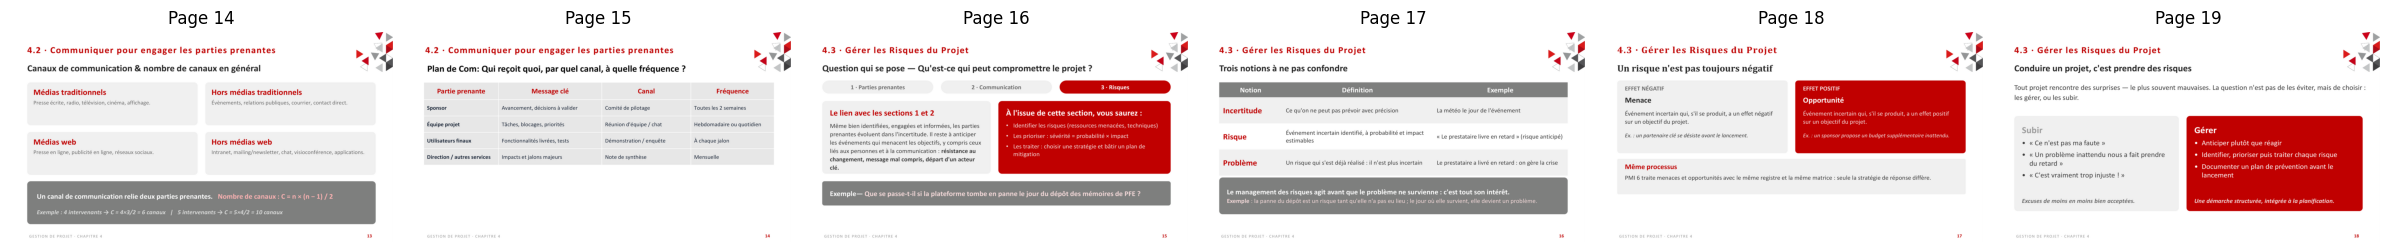

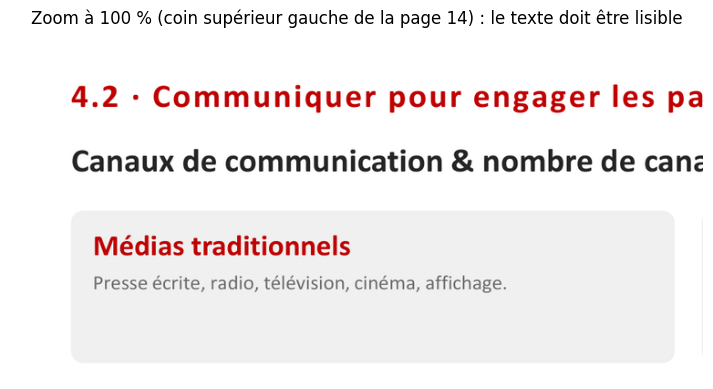

⏱️  Conversion des pages en images : 2.1 s | énergie GPU ≈ 0.04 Wh


{'etape': 'Conversion des pages en images',
 't_debut': 728.440819603,
 't_fin': 730.510760537,
 'duree_s': 2.0699409339999875,
 'temps_cpu_s': 2.030000000000001,
 'gpu0_pic_pytorch_mo': 6313.25537109375,
 'gpu1_pic_pytorch_mo': 8849.943359375,
 'ram_pic_mo': 2109.0,
 'cpu_moyen_pct': 97.82000000000001,
 'gpu0_util_moy_pct': 0.0,
 'gpu0_util_max_pct': 0.0,
 'gpu0_occupe_pic_mo': 6903.1875,
 'gpu0_puissance_moy_w': 30.808,
 'gpu0_energie_wh': 0.01771409452629767,
 'gpu1_util_moy_pct': 0.0,
 'gpu1_util_max_pct': 0.0,
 'gpu1_occupe_pic_mo': 9443.1875,
 'gpu1_puissance_moy_w': 33.472,
 'gpu1_energie_wh': 0.019245850817457662,
 'energie_gpu_wh': 0.03695994534375533}

In [18]:
PERF.debut("Conversion des pages en images")
TAILLE_PATCH_PX = 16          # Gemma 4 découpe l'image en patchs de 16 x 16 px…
NOYAU_REGROUPEMENT = 3        # … puis regroupe 3 x 3 patchs : 1 token visuel = 48 x 48 px
BUDGETS_POSSIBLES = (70, 140, 280, 560, 1120)
DOSSIER_PAGES = os.path.join(DOSSIER_TRAVAIL, "pages")
assert TOKENS_PAR_PAGE in BUDGETS_POSSIBLES, f"TOKENS_PAR_PAGE doit être l'une des valeurs {BUDGETS_POSSIBLES}"


def taille_vue_par_gemma(largeur, hauteur, budget):
    """Taille (largeur, hauteur) à laquelle le processor de Gemma 4 ramène une image pour ce budget de tokens."""
    h, w = get_aspect_ratio_preserving_size(height=hauteur, width=largeur, patch_size=TAILLE_PATCH_PX,
                                            max_patches=budget * NOYAU_REGROUPEMENT ** 2,
                                            pooling_kernel_size=NOYAU_REGROUPEMENT)
    return w, h


def tokens_image(largeur, hauteur):
    return (largeur // TAILLE_PATCH_PX) * (hauteur // TAILLE_PATCH_PX) // NOYAU_REGROUPEMENT ** 2


def texte_de_la_page(page, max_caracteres=MAX_CARACTERES_TEXTE_PAGE):
    """Texte de la couche texte du PDF (vide pour un PDF scanné), nettoyé."""
    try:
        brut = page.get_text("text", sort=True)
    except Exception:
        return ""
    brut = unicodedata.normalize("NFC", brut)
    lignes = []
    for ligne in brut.splitlines():
        ligne = "".join(c if unicodedata.category(c)[0] != "C" else " " for c in ligne)
        ligne = re.sub(r"\s+", " ", ligne).strip()
        if ligne:
            lignes.append(ligne)
    return "\n".join(lignes)[:max_caracteres]


def rendre_pages(doc, budget, dossier):
    """Rend chaque page en image RGB à la taille exacte que verra Gemma 4, l'enregistre en PNG et extrait son texte."""
    os.makedirs(dossier, exist_ok=True)
    for ancien in os.listdir(dossier):
        if ancien.startswith("page_") and ancien.endswith(".png"):
            os.remove(os.path.join(dossier, ancien))
    pages = []
    for numero in NUMEROS_PAGES:
        page = doc[numero - 1]
        w, h = taille_vue_par_gemma(round(page.rect.width), round(page.rect.height), budget)
        zoom = min(max(1.0, 1.2 * max(w / page.rect.width, h / page.rect.height)), 300 / 72)   # un peu plus grand, puis réduit
        pix = page.get_pixmap(matrix=pymupdf.Matrix(zoom, zoom), alpha=False)
        image = Image.frombytes("RGB", (pix.width, pix.height), pix.samples)
        for _ in range(3):        # le processor recalcule la taille à partir de l'image : on se place sur sa taille finale
            w, h = taille_vue_par_gemma(image.width, image.height, budget)
            if (w, h) == image.size:
                break
            image = image.resize((w, h), Image.LANCZOS)
        chemin = os.path.join(dossier, f"page_{numero:03d}.png")
        image.save(chemin)
        pages.append({"numero": numero, "image": image, "chemin": chemin, "largeur": image.width,
                      "hauteur": image.height, "tokens": tokens_image(image.width, image.height),
                      "texte": texte_de_la_page(page) if AJOUTER_TEXTE_PDF else ""})
    return pages


PAGES = rendre_pages(DOC_PDF, TOKENS_PAR_PAGE, DOSSIER_PAGES)

# --- Vérifications ---
assert len(PAGES) == N_PAGES, "Toutes les pages n'ont pas été converties"
assert [p["numero"] for p in PAGES] == NUMEROS_PAGES, "Ordre des pages non conservé"
assert all(p["tokens"] <= TOKENS_PAR_PAGE for p in PAGES)
TOKENS_IMAGES_TOTAL = sum(p["tokens"] for p in PAGES)
print(f"Budget : {TOKENS_PAR_PAGE} tokens maximum par page (1 token = {TAILLE_PATCH_PX * NOYAU_REGROUPEMENT} x "
      f"{TAILLE_PATCH_PX * NOYAU_REGROUPEMENT} px)")
for p in PAGES:
    print(f"   Page {p['numero']} → {os.path.basename(p['chemin'])} : {p['largeur']} × {p['hauteur']} px → {p['tokens']} tokens"
          + (f" + {len(p['texte'])} caractères de texte" if AJOUTER_TEXTE_PDF else ""))
print(f"✅ {len(PAGES)} images créées dans l'ordre du PDF — {TOKENS_IMAGES_TOTAL} tokens visuels au total")
if AJOUTER_TEXTE_PDF:
    sans_texte = [p["numero"] for p in PAGES if not p["texte"]]
    if sans_texte:
        print(f"ℹ️  Pas de texte extractible pour les pages {sans_texte} (PDF scanné ?) : le modèle lira seulement l'image.")
    print(f"\nTexte extrait de la page {PAGES[0]['numero']} (début) :\n{PAGES[0]['texte'][:400] or '—'}")

# --- Aperçu : miniatures + zoom à 100 % pour contrôler la lisibilité ---
n_apercu = min(len(PAGES), 6)
fig, axes = plt.subplots(1, n_apercu, figsize=(4 * n_apercu, 5.5))
for ax, p in zip(np.atleast_1d(axes), PAGES[:n_apercu]):
    ax.imshow(p["image"]); ax.set_title(f"Page {p['numero']}"); ax.axis("off")
plt.tight_layout(); plt.show()
p0 = PAGES[0]["image"]
plt.figure(figsize=(9, 4.5))
plt.imshow(p0.crop((0, 0, min(p0.width, 760), min(p0.height, 380))))
plt.title(f"Zoom à 100 % (coin supérieur gauche de la page {PAGES[0]['numero']}) : le texte doit être lisible")
plt.axis("off"); plt.show()
PERF.fin()

## 9. Préparation de l'audio

L'original est copié tel quel (jamais modifié). Une version mono 16 kHz est préparée pour le modèle.

**Limite de Gemma 4 : 30 s par élément audio.** Au-delà, le processor coupe la fin sans prévenir. L'audio est donc
découpé en morceaux de 30 s au plus, **coupés dans les silences** (pour ne pas couper un mot), et **tous les morceaux sont
envoyés dans la même requête**, dans l'ordre : c'est toujours une seule inférence.

In [19]:
PERF.debut("Préparation de l'audio")
EXTENSIONS_AUDIO = (".wav", ".mp3")
EXTENSIONS_AUDIO_TOLEREES = (".flac", ".ogg", ".m4a", ".aac", ".opus", ".webm")   # lues si possible (non garanti)
DOSSIER_AUDIO = os.path.join(DOSSIER_TRAVAIL, "audio")
os.makedirs(DOSSIER_AUDIO, exist_ok=True)


def lire_audio(chemin):
    """Lit un fichier audio en float32 de forme (échantillons, canaux), sans le modifier."""
    try:
        info = sf.info(chemin)
        signal, freq = sf.read(chemin, dtype="float32", always_2d=True)
        return signal, freq, f"soundfile (libsndfile {sf.__libsndfile_version__}), {info.format} / {info.subtype}"
    except Exception as e:
        y, freq = librosa.load(chemin, sr=None, mono=False)   # secours : décodage via audioread / ffmpeg
        signal = np.atleast_2d(y).T.astype(np.float32)
        return signal, int(freq), f"librosa (secours après échec de soundfile : {type(e).__name__})"


def formater_duree(secondes):
    return f"{int(secondes // 60)} min {secondes % 60:04.1f} s"


# --- 9.1 Localisation de l'audio (fourni via CHEMIN_AUDIO, ou cherché dans /kaggle/input) ---
UTILISE_DEMO_AUDIO = False   # conservé pour la traçabilité (toujours False : pas de mode démonstration)
if CHEMIN_AUDIO is None:
    audios_trouves = fichiers_presents(DOSSIER_ENTREES, EXTENSIONS_AUDIO)
    if not audios_trouves:
        audios_trouves = fichiers_presents(DOSSIER_ENTREES, EXTENSIONS_AUDIO_TOLEREES)
        if audios_trouves:
            print(f"⚠️  Aucun WAV/MP3, mais un autre format audio a été trouvé : {audios_trouves[0]} "
                  "(lecture tentée ; en cas d'échec, convertissez-le en WAV ou MP3).")
    if not audios_trouves:
        raise FileNotFoundError(
            f"❌ Aucun fichier WAV/MP3 trouvé dans {DOSSIER_ENTREES}. Renseignez CHEMIN_AUDIO ou ajoutez-le via Add Input → Upload.")
    CHEMIN_AUDIO = audios_trouves[0]
    if len(audios_trouves) > 1:
        print("⚠️  Plusieurs audios trouvés (le premier est utilisé ; sinon renseignez CHEMIN_AUDIO) :")
        for a in audios_trouves:
            print("     -", a)
if not os.path.isfile(CHEMIN_AUDIO):
    raise FileNotFoundError(f"❌ Fichier audio introuvable : {CHEMIN_AUDIO}")
extension = os.path.splitext(CHEMIN_AUDIO)[1].lower()
if extension not in EXTENSIONS_AUDIO:
    print(f"⚠️  Extension {extension} : seuls WAV et MP3 sont garantis ; tentative de lecture quand même.")

# --- 9.2 Conservation de l'original (copie binaire identique, jamais modifiée) ---
CHEMIN_AUDIO_ORIGINAL = os.path.join(DOSSIER_AUDIO, "original" + extension)
shutil.copyfile(CHEMIN_AUDIO, CHEMIN_AUDIO_ORIGINAL)
SHA256_AUDIO = empreinte_sha256(CHEMIN_AUDIO)
assert empreinte_sha256(CHEMIN_AUDIO_ORIGINAL) == SHA256_AUDIO, "La copie de l'original n'est pas identique"

# --- 9.3 Lecture et contrôles de qualité ---
signal, FREQ_ORIGINE, lecteur = lire_audio(CHEMIN_AUDIO)
DUREE_AUDIO_S = signal.shape[0] / FREQ_ORIGINE
if signal.shape[0] == 0 or DUREE_AUDIO_S < 3:
    raise ValueError(f"❌ Audio vide ou trop court ({DUREE_AUDIO_S:.1f} s) : au moins quelques secondes de parole sont nécessaires.")
crete = float(np.max(np.abs(signal)))
rms_db = 20 * np.log10(float(np.sqrt(np.mean(signal ** 2))) + 1e-12)
sature = float(np.mean(np.abs(signal) >= 0.999))
trames = signal.mean(axis=1)[: len(signal) // 400 * 400].reshape(-1, 400)   # trames de ~25 ms à 16 kHz
silence = float(np.mean(20 * np.log10(np.sqrt(np.mean(trames ** 2, axis=1)) + 1e-12) < -45)) if len(trames) else 0.0
print(f"✅ Audio : {CHEMIN_AUDIO}  (lu avec {lecteur})")
print(f"   Durée {formater_duree(DUREE_AUDIO_S)} | {FREQ_ORIGINE} Hz | {signal.shape[1]} canal(aux) | "
      f"crête {crete:.2f} | niveau moyen {rms_db:.1f} dBFS | saturation {100 * sature:.2f} % | silence ≈ {100 * silence:.0f} %")
print(f"   Original conservé à l'identique : {CHEMIN_AUDIO_ORIGINAL} (SHA-256 {SHA256_AUDIO[:16]}…)")
if crete < 0.05:
    print("⚠️  Niveau très faible : rapprochez le micro ou parlez plus fort pour une meilleure compréhension.")
if sature > 0.001:
    print("⚠️  Saturation détectée : baissez le gain du micro lors de l'enregistrement.")
if silence > 0.6:
    print("⚠️  L'enregistrement contient surtout du silence.")
if not 60 <= DUREE_AUDIO_S <= 120:
    print("ℹ️  Pour le premier test, un audio de 1 à 2 minutes est recommandé.")

# --- 9.4 Préparation au format Gemma 4 : mono, 16 kHz, float32 dans [-1, 1] (aucune transcription) ---
mono = signal.mean(axis=1) if signal.shape[1] > 1 else signal[:, 0]
if FREQ_ORIGINE != FREQ_MODELE:
    audio_16k = librosa.resample(mono, orig_sr=FREQ_ORIGINE, target_sr=FREQ_MODELE, res_type="soxr_hq")
else:
    audio_16k = mono.copy()
# Normalisation du volume (version envoyée au modèle seulement ; l'original reste intact)
GAIN_VOLUME_DB = 0.0
crete_16k = float(np.max(np.abs(audio_16k))) if len(audio_16k) else 0.0
if NORMALISER_VOLUME and crete_16k > 1e-4:
    GAIN_VOLUME_DB = 20 * np.log10(0.9 / crete_16k)
    audio_16k = audio_16k * np.float32(0.9 / crete_16k)
    print(f"🔊 Volume normalisé pour le modèle : gain de {GAIN_VOLUME_DB:+.1f} dB (crête {crete_16k:.2f} → 0.90)")
AUDIO_16K = np.ascontiguousarray(np.nan_to_num(audio_16k), dtype=np.float32)
del signal, mono, audio_16k
assert AUDIO_16K.ndim == 1 and AUDIO_16K.dtype == np.float32
assert abs(len(AUDIO_16K) / FREQ_MODELE - DUREE_AUDIO_S) < 0.01, "La durée a changé lors du rééchantillonnage"

# --- 9.5 Découpage en morceaux de 30 s au plus (limite de Gemma 4), tous envoyés dans le MÊME message ---
assert DUREE_MAX_SEGMENT_S <= 30, "Gemma 4 n'accepte pas plus de 30 s par élément audio"


def decouper_aux_silences(signal, freq, duree_max_s, duree_min_s=None, fenetre_s=0.05):
    """Coupe le signal en morceaux de duree_max_s au plus, à l'endroit le plus calme (fenêtres de 50 ms) situé entre
    duree_min_s et duree_max_s après le début du morceau : on évite de couper un mot en deux."""
    n_max = int(duree_max_s * freq) - int(0.1 * freq)                  # petite marge sous la limite
    n_min = int((duree_min_s if duree_min_s is not None else 0.66 * duree_max_s) * freq)
    fen = int(fenetre_s * freq)
    morceaux, debut = [], 0
    while len(signal) - debut > n_max:
        zone = signal[debut + n_min: debut + n_max]
        nb = len(zone) // fen
        energie = (zone[: nb * fen].reshape(nb, fen) ** 2).mean(axis=1)
        coupe = debut + n_min + int(np.argmin(energie)) * fen + fen // 2
        morceaux.append(signal[debut:coupe])
        debut = coupe
    morceaux.append(signal[debut:])
    return morceaux


SEGMENTS_AUDIO = decouper_aux_silences(AUDIO_16K, FREQ_MODELE, DUREE_MAX_SEGMENT_S)
if len(SEGMENTS_AUDIO) > 1 and len(SEGMENTS_AUDIO[-1]) < 0.5 * FREQ_MODELE:   # fin < 0,5 s : silence de fin, ignoré
    SEGMENTS_AUDIO = SEGMENTS_AUDIO[:-1]
assert all(len(s) <= DUREE_MAX_SEGMENT_S * FREQ_MODELE for s in SEGMENTS_AUDIO), "Un morceau dépasse 30 s"
assert sum(len(s) for s in SEGMENTS_AUDIO) >= len(AUDIO_16K) - FREQ_MODELE // 2, "Une partie de l'audio a été perdue"
CHEMIN_AUDIO_16K = os.path.join(DOSSIER_AUDIO, "audio_16k_mono.wav")
sf.write(CHEMIN_AUDIO_16K, AUDIO_16K, FREQ_MODELE, subtype="FLOAT")
print(f"✅ Audio préparé : mono, {FREQ_MODELE} Hz, {len(AUDIO_16K)} échantillons ({formater_duree(len(AUDIO_16K) / FREQ_MODELE)}) "
      f"→ {len(SEGMENTS_AUDIO)} élément(s) audio ; copie de contrôle : {CHEMIN_AUDIO_16K}")
for k, seg in enumerate(SEGMENTS_AUDIO, start=1):
    print(f"   Partie {k}/{len(SEGMENTS_AUDIO)} : {len(seg) / FREQ_MODELE:5.1f} s")
if len(SEGMENTS_AUDIO) > 1:
    print(f"ℹ️  Audio > {DUREE_MAX_SEGMENT_S} s : découpé (dans les silences) en {len(SEGMENTS_AUDIO)} parties "
          "consécutives, toutes envoyées dans la même requête.")
print(f"   Tokens audio attendus ≈ {int(len(AUDIO_16K) / FREQ_MODELE * 25)} (25 tokens par seconde)")
PERF.fin()

# --- Écoute ---
if os.path.getsize(CHEMIN_AUDIO) <= 8 * 2**20:
    print("▶️  Enregistrement original :"); display(LecteurAudio(filename=CHEMIN_AUDIO))
print("▶️  Version envoyée au modèle (16 kHz mono" + (", volume normalisé" if NORMALISER_VOLUME else "") + ") — 60 premières secondes :")
display(LecteurAudio(data=AUDIO_16K[: 60 * FREQ_MODELE], rate=FREQ_MODELE))

✅ Audio : /kaggle/input/datasets/eyajall/communication/Voix_261123_202702.mp3  (lu avec soundfile (libsndfile 1.2.2), MP3 / MPEG_LAYER_III)
   Durée 0 min 15.8 s | 48000 Hz | 1 canal(aux) | crête 0.26 | niveau moyen -28.9 dBFS | saturation 0.00 % | silence ≈ 49 %
   Original conservé à l'identique : /kaggle/working/analyse_gemma4/audio/original.mp3 (SHA-256 30212b5555f384de…)
ℹ️  Pour le premier test, un audio de 1 à 2 minutes est recommandé.
🔊 Volume normalisé pour le modèle : gain de +10.7 dB (crête 0.26 → 0.90)
✅ Audio préparé : mono, 16000 Hz, 252246 échantillons (0 min 15.8 s) → 1 élément(s) audio ; copie de contrôle : /kaggle/working/analyse_gemma4/audio/audio_16k_mono.wav
   Partie 1/1 :  15.8 s
   Tokens audio attendus ≈ 394 (25 tokens par seconde)
⏱️  Préparation de l'audio : 18.0 s | énergie GPU ≈ 0.32 Wh
▶️  Enregistrement original :


▶️  Version envoyée au modèle (16 kHz mono, volume normalisé) — 60 premières secondes :


## 10. Construction de la requête 

In [20]:
PERF.debut("Construction de la requête")
# Gemma 4 accepte un message système (nouveauté de Gemma 4) ; il n'impose pas de texte officiel.
PROMPT_SYSTEME = "Tu es un enseignant expert et rigoureux. Tu réponds toujours en français."


def construire_consigne(n_pages, n_parties_audio=1):
    parties = "" if n_parties_audio == 1 else f" (en {n_parties_audio} parties consécutives)"
    aide_texte = (" Sous chaque image, le texte de la page extrait du PDF est aussi fourni : sers-t'en pour recopier "
                  "exactement ce que dit le cours." if AJOUTER_TEXTE_PDF else "")
    return f"""Tu es un enseignant expert et rigoureux. Ta tâche : vérifier l'explication orale d'un étudiant en la comparant à son support de cours, puis repérer ses erreurs.

DONNÉES FOURNIES DANS CE MESSAGE :
- Les {n_pages} images ci-dessus sont des pages du cours, dans l'ordre ; le numéro de chaque page (« Page X ») est indiqué juste avant son image.{aide_texte}
- L'enregistrement audio placé juste après cette consigne{parties} est l'explication orale de l'étudiant, avec ses propres mots.

TRAVAILLE EN DEUX ÉTAPES ET ÉCRIS LES DEUX ÉTAPES DANS TA RÉPONSE.

ÉTAPE 1 — ÉCOUTE. Écoute l'audio en entier et écris, dans l'ordre, chaque affirmation de l'étudiant (une idée par ligne, numérotée A1, A2, A3…), en reprenant ses mots le plus fidèlement possible. N'ajoute rien qu'il n'a pas dit. Si un passage est inaudible, écris « [inaudible] ».

ÉTAPE 2 — VÉRIFICATION. Pour CHAQUE affirmation de l'étape 1, sans en sauter aucune :
1. trouve la page du cours qui traite de cette notion ;
2. recopie ce que dit le cours sur cette notion ;
3. compare mot à mot l'affirmation et le cours. Ne suppose pas que l'étudiant a raison : vérifie les définitions, les exemples, les chiffres et surtout les inversions entre deux notions (attribuer à une notion ce que le cours dit d'une autre), qui sont les erreurs les plus fréquentes ;
4. donne un verdict :
   - CORRECT : l'affirmation est conforme au cours ;
   - INCORRECT : elle contredit le cours ou elle est fausse (définition incorrecte, notions inversées, exemple mal attribué, chiffre ou formule faux, raisonnement incohérent). Si deux notions sont inversées, chaque affirmation concernée est INCORRECT ;
   - NON VÉRIFIABLE : le cours n'en parle pas, ou le passage est inaudible ;
5. si le verdict est INCORRECT, explique pourquoi et donne la correction selon le cours.
Une notion que l'étudiant n'a pas mentionnée n'est jamais une erreur : ne signale aucun oubli. N'invente aucun contenu.

FORMAT DE LA RÉPONSE (Markdown, en français, exactement cette structure) :

## Étape 1 — Affirmations de l'étudiant
A1 : « … »
A2 : « … »

## Étape 2 — Vérification

### A1
- **Page :** …
- **Le cours dit :** « … »
- **Verdict :** CORRECT, INCORRECT ou NON VÉRIFIABLE
- **Pourquoi :** …
- **Correction :** …

### A2
(même structure, et ainsi de suite pour chaque affirmation ; si le verdict n'est pas INCORRECT, écris « — » pour Pourquoi et Correction)"""


def construire_conversation(pages, segments_audio, consigne):
    """UN SEUL message utilisateur : toutes les pages (+ leur texte), la consigne, puis l'audio.
    Ordre conseillé par Google pour Gemma 4 : les images avant le texte, l'audio après le texte."""
    duree_totale = sum(len(s) for s in segments_audio) / FREQ_MODELE
    contenu = [{"type": "text", "text": f"Voici le support de cours de l'étudiant ({len(pages)} page(s), dans l'ordre) :\n"}]
    for p in pages:
        contenu.append({"type": "text", "text": f"\n--- Page {p['numero']}/{N_PAGES_PDF} ---\n"})
        contenu.append({"type": "image", "image": p["image"]})          # déjà à la taille exacte vue par Gemma 4
        if AJOUTER_TEXTE_PDF and p.get("texte"):
            contenu.append({"type": "text", "text": f"\nTexte de la page {p['numero']} (extrait du PDF) :\n{p['texte']}\n"})
    contenu.append({"type": "text", "text": "\n\n" + consigne})
    contenu.append({"type": "text", "text": "\n\nVoici l'enregistrement audio original de l'explication orale de "
                                            f"l'étudiant (durée : {formater_duree(duree_totale)}) :\n"})
    for k, segment in enumerate(segments_audio, start=1):
        if len(segments_audio) > 1:
            contenu.append({"type": "text", "text": f"\n[Partie {k}/{len(segments_audio)} de l'enregistrement]\n"})
        contenu.append({"type": "audio", "audio": segment})          # signal brut 16 kHz (np.ndarray float32)
    return [
        {"role": "system", "content": [{"type": "text", "text": PROMPT_SYSTEME}]},
        {"role": "user", "content": contenu},
    ]


def decrire_conversation(conversation):
    """Affiche la structure de la conversation (sans afficher les données brutes)."""
    for message in conversation:
        print(f"[{message['role']}]")
        for element in message["content"]:
            if element["type"] == "image":
                print(f"   🖼️  image {element['image'].size[0]}×{element['image'].size[1]} px")
            elif element["type"] == "audio":
                print(f"   🔊 audio : np.ndarray {element['audio'].dtype}, {len(element['audio'])} échantillons "
                      f"= {len(element['audio']) / FREQ_MODELE:.1f} s à {FREQ_MODELE} Hz")
            else:
                texte = element["text"].strip().replace("\n", " ⏎ ")
                print(f"   📝 texte : {texte[:90]}{'…' if len(texte) > 90 else ''}")


# Début de réponse imposé : le modèle doit écrire tout de suite la 1re affirmation entendue
# (il ne peut plus recopier le modèle de réponse « A1 : « … » » de la consigne).
PREFIXE_REPONSE = "## Étape 1 — Affirmations de l'étudiant\nA1 : «"
CONSIGNE = construire_consigne(N_PAGES, len(SEGMENTS_AUDIO))
CONVERSATION = construire_conversation(PAGES, SEGMENTS_AUDIO, CONSIGNE)
decrire_conversation(CONVERSATION)

# --- Vérifications de structure ---
messages_utilisateur = [m for m in CONVERSATION if m["role"] == "user"]
elements = messages_utilisateur[0]["content"]
n_images = sum(e["type"] == "image" for e in elements)
n_audios = sum(e["type"] == "audio" for e in elements)
assert len(messages_utilisateur) == 1, "Il doit y avoir exactement UN message utilisateur"
assert n_images == N_PAGES, "Toutes les pages doivent être dans le message"
assert n_audios == len(SEGMENTS_AUDIO) >= 1, "L'audio doit être dans le même message"
assert all(isinstance(e["audio"], np.ndarray) for e in elements if e["type"] == "audio"), "L'audio doit être le signal brut"
ordre_pages = [int(re.search(r"Page (\d+)/", e["text"]).group(1)) for e in elements
               if e["type"] == "text" and e["text"].strip().startswith("--- Page")]
assert ordre_pages == NUMEROS_PAGES, "Les pages doivent être dans l'ordre du PDF"
assert "Aucune erreur détectée" not in CONSIGNE, "La consigne ne doit pas proposer de réponse toute faite"
os.makedirs(os.path.join(DOSSIER_TRAVAIL, "resultats"), exist_ok=True)
with open(os.path.join(DOSSIER_TRAVAIL, "resultats", "consigne.txt"), "w", encoding="utf-8") as f:
    f.write(CONSIGNE)
n_car_texte_pdf = sum(len(p.get("texte", "")) for p in PAGES) if AJOUTER_TEXTE_PDF else 0
print(f"\n✅ Requête unique prête : 1 message utilisateur = {n_images} image(s) + {n_audios} audio + consigne "
      f"({len(CONSIGNE)} caractères)" + (f" + texte du PDF ({n_car_texte_pdf} caractères)" if n_car_texte_pdf else ""))
PERF.fin()

[system]
   📝 texte : Tu es un enseignant expert et rigoureux. Tu réponds toujours en français.
[user]
   📝 texte : Voici le support de cours de l'étudiant (7 page(s), dans l'ordre) :
   📝 texte : --- Page 14/31 ---
   🖼️  image 1488×816 px
   📝 texte : Texte de la page 14 (extrait du PDF) : ⏎ 4.2 · Communiquer pour engager les parties prenan…
   📝 texte : --- Page 15/31 ---
   🖼️  image 1488×816 px
   📝 texte : Texte de la page 15 (extrait du PDF) : ⏎ 4.2 · Communiquer pour engager les parties prenan…
   📝 texte : --- Page 16/31 ---
   🖼️  image 1488×816 px
   📝 texte : Texte de la page 16 (extrait du PDF) : ⏎ 4.3 · Gérer les Risques du Projet ⏎ Question qui …
   📝 texte : --- Page 17/31 ---
   🖼️  image 1488×816 px
   📝 texte : Texte de la page 17 (extrait du PDF) : ⏎ 4.3 · Gérer les Risques du Projet ⏎ Trois notions…
   📝 texte : --- Page 18/31 ---
   🖼️  image 1488×816 px
   📝 texte : Texte de la page 18 (extrait du PDF) : ⏎ 4.3 · Gérer les Risques du Projet ⏎ Un risque n'e…
   📝 t

{'etape': 'Construction de la requête',
 't_debut': 1394.086105139,
 't_fin': 1394.099489422,
 'duree_s': 0.013384283000050345,
 'temps_cpu_s': 0.010000000000019327,
 'gpu0_pic_pytorch_mo': 6313.25537109375,
 'gpu1_pic_pytorch_mo': 8849.943359375,
 'ram_pic_mo': 2174.26953125,
 'cpu_moyen_pct': 143.0,
 'gpu0_util_moy_pct': 0.0,
 'gpu0_util_max_pct': 0.0,
 'gpu0_occupe_pic_mo': 6903.1875,
 'gpu0_puissance_moy_w': 31.525,
 'gpu0_energie_wh': 0.00011720542266016308,
 'gpu1_util_moy_pct': 0.0,
 'gpu1_util_max_pct': 0.0,
 'gpu1_occupe_pic_mo': 9443.1875,
 'gpu1_puissance_moy_w': 34.435,
 'gpu1_energie_wh': 0.00012802438475187047,
 'energie_gpu_wh': 0.0002452298074120335}

## 11. Entrées du modèle


In [21]:
PERF.debut("Préparation des entrées (processor)")
LIMITE_CONTEXTE = CONFIG.get_text_config().max_position_embeddings     # 131 072 tokens pour E4B


def preparer_entrees(conversation, budget_page):
    """Gabarit officiel de Gemma 4 (sans « réflexion ») + début de réponse imposé, puis tokens + images + audio."""
    texte = processor.apply_chat_template(conversation, add_generation_prompt=True, tokenize=False,
                                          enable_thinking=False) + PREFIXE_REPONSE
    images = [e["image"] for m in conversation for e in m["content"] if e["type"] == "image"]
    audios = [e["audio"] for m in conversation for e in m["content"] if e["type"] == "audio"]
    entrees = processor(text=texte, images=images, audio=audios, return_tensors="pt",
                        text_kwargs={"add_special_tokens": False},          # le gabarit contient déjà <bos>
                        images_kwargs={"max_soft_tokens": budget_page})
    return texte, entrees


def tokens_audio_attendus(segment):
    """Nombre de tokens que le processor réserve pour un élément audio (25 par seconde, 750 au plus)."""
    if hasattr(processor, "_compute_audio_num_tokens"):
        return processor._compute_audio_num_tokens(segment, FREQ_MODELE)
    return min(processor.audio_seq_length, math.ceil(len(segment) / FREQ_MODELE * 1000 / processor.audio_ms_per_token))


def carte_sequence(ids):
    """Résume la séquence en blocs successifs : texte / image / audio."""
    blocs = []
    for t in ids:
        nature = "image" if t == ID_IMAGE else "audio" if t == ID_AUDIO else "texte"
        if blocs and blocs[-1][0] == nature:
            blocs[-1][1] += 1
        else:
            blocs.append([nature, 1])
    return blocs


TEXTE_GABARIT, ENTREES = preparer_entrees(CONVERSATION, TOKENS_PAR_PAGE)
ids = ENTREES["input_ids"][0].tolist()
N_TOKENS_ENTREE = len(ids)
N_TOKENS_IMAGE = ids.count(ID_IMAGE)
N_TOKENS_AUDIO = ids.count(ID_AUDIO)
TOKENS_AUDIO_ATTENDUS = sum(tokens_audio_attendus(s) for s in SEGMENTS_AUDIO)

print("Tenseurs transmis au modèle :")
for nom, valeur in ENTREES.items():
    print(f"   {nom:22s} {tuple(valeur.shape)} {str(valeur.dtype).replace('torch.', '')}")
print(f"\nSéquence unique de {N_TOKENS_ENTREE} tokens : {N_TOKENS_IMAGE} tokens image + {N_TOKENS_AUDIO} tokens audio "
      f"+ {N_TOKENS_ENTREE - N_TOKENS_IMAGE - N_TOKENS_AUDIO} tokens de texte")
print(f"Part de l'audio dans l'entrée : {100 * N_TOKENS_AUDIO / N_TOKENS_ENTREE:.0f} % "
      f"(images : {100 * N_TOKENS_IMAGE / N_TOKENS_ENTREE:.0f} %)")
print("Ordre dans la séquence : " + " → ".join(f"{nature}({n})" for nature, n in carte_sequence(ids)))

# --- Vérifications ---
assert ENTREES["input_ids"].shape[0] == 1, "Une seule séquence (une seule requête)"
assert ENTREES["pixel_values"].shape[0] == N_PAGES, "Chaque page doit être une image distincte"
assert N_TOKENS_IMAGE == TOKENS_IMAGES_TOTAL, (f"Tokens image incohérents : {N_TOKENS_IMAGE} dans la séquence, "
                                              f"{TOKENS_IMAGES_TOTAL} attendus")
assert ENTREES["input_features"].shape[0] == len(SEGMENTS_AUDIO), "Chaque partie de l'audio doit être un élément distinct"
assert N_TOKENS_AUDIO == TOKENS_AUDIO_ATTENDUS > 0, (f"Audio incomplet : {N_TOKENS_AUDIO} tokens dans la séquence, "
                                                   f"{TOKENS_AUDIO_ATTENDUS} attendus (audio tronqué ?)")
assert ids[0] == processor.tokenizer.bos_token_id and ids[1] != processor.tokenizer.bos_token_id, "<bos> absent ou doublé"
assert N_TOKENS_ENTREE + MAX_NOUVEAUX_TOKENS <= LIMITE_CONTEXTE, "Séquence trop longue pour le contexte du modèle"

# Le seul texte de la séquence est notre gabarit (étiquettes + consigne) : aucune transcription n'y a été insérée
ids_texte = [t for t in ids if t not in (ID_IMAGE, ID_AUDIO) and t not in IDS_BORNES]
texte_relu = processor.tokenizer.decode(ids_texte, skip_special_tokens=False, clean_up_tokenization_spaces=False)
gabarit_sans_medias = TEXTE_GABARIT.replace(processor.image_token, "").replace(processor.audio_token, "")
TEXTE_SEQUENCE_CONFORME = texte_relu == gabarit_sans_medias
if not TEXTE_SEQUENCE_CONFORME:      # montre le premier endroit différent (souvent un caractère rare du PDF)
    k = next((i for i, (x, y) in enumerate(zip(texte_relu, gabarit_sans_medias)) if x != y),
             min(len(texte_relu), len(gabarit_sans_medias)))
    print(f"ℹ️  Texte relu ≠ gabarit à la position {k} : relu {texte_relu[k:k + 40]!r} / gabarit {gabarit_sans_medias[k:k + 40]!r}")
print(f"✅ Pages : {N_PAGES} images, {N_TOKENS_IMAGE} tokens | Audio : {len(SEGMENTS_AUDIO)} partie(s), "
      f"{N_TOKENS_AUDIO} tokens = {len(AUDIO_16K) / FREQ_MODELE:.1f} s, non tronqué | "
      + ("texte = gabarit uniquement" if TEXTE_SEQUENCE_CONFORME else "⚠️ texte relu différent du gabarit (à vérifier)"))
with open(os.path.join(DOSSIER_TRAVAIL, "resultats", "gabarit_requete.txt"), "w", encoding="utf-8") as f:
    f.write(TEXTE_GABARIT)

# --- Estimation de la mémoire de calcul pour cette séquence ---
def valeur_config(cfg, nom, defaut):
    """Lit un réglage de la configuration (certains réglages de Gemma 4 varient d'une couche à l'autre)."""
    try:
        v = getattr(cfg, nom)
        return defaut if v is None else v
    except Exception:
        return defaut


cfg_texte = CONFIG.get_text_config()
couches_cache = valeur_config(cfg_texte, "num_hidden_layers", 42) - valeur_config(cfg_texte, "num_kv_shared_layers", 0)
tete = max(valeur_config(cfg_texte, "head_dim", 256), valeur_config(cfg_texte, "global_head_dim", 0))
tetes_kv = valeur_config(cfg_texte, "num_key_value_heads", 2)
tetes = valeur_config(cfg_texte, "num_attention_heads", 8)
cache_kv_gio = couches_cache * 2 * (N_TOKENS_ENTREE + MAX_NOUVEAUX_TOKENS) * tetes_kv * tete * 2 / 2**30
attention_gio = tetes * N_TOKENS_ENTREE ** 2 * 4 / 2**30          # matrice d'attention d'une couche (noyau « math »)
mesurer_memoire_libre(GPU_UTILISABLES)
libre_min = min(g["libre_gio"] for g in GPU_UTILISABLES)
print(f"Mémoire de calcul estimée : cache KV ≤ {cache_kv_gio:.2f} Gio, attention d'une couche ≤ {attention_gio:.2f} Gio ; "
      f"mémoire libre minimale sur un GPU : {libre_min:.2f} Gio")
if attention_gio + cache_kv_gio > libre_min:
    print("⚠️  Marge mémoire faible : en cas d'erreur mémoire, la résolution des pages sera réduite automatiquement.")

# --- Transfert vers le GPU de la couche d'entrée (accelerate déplace ensuite les tenseurs entre GPU) ---
PERIPHERIQUE_ENTREE = model.get_input_embeddings().weight.device
ENTREES_MODELE = ENTREES.to(PERIPHERIQUE_ENTREE).to(DTYPE)   # seuls les tenseurs flottants changent de précision
print(f"✅ Entrées placées sur {PERIPHERIQUE_ENTREE} : pixel_values {ENTREES_MODELE['pixel_values'].dtype}, "
      f"input_features {ENTREES_MODELE['input_features'].dtype}")
PERF.fin()

Tenseurs transmis au modèle :
   input_ids              (1, 6300) int64
   attention_mask         (1, 6300) int64
   mm_token_type_ids      (1, 6300) int64
   pixel_values           (7, 5040, 768) float32
   image_position_ids     (7, 5040, 2) int64
   input_features         (1, 1576, 128) float32
   input_features_mask    (1, 1576) bool

Séquence unique de 6300 tokens : 3689 tokens image + 394 tokens audio + 2217 tokens de texte
Part de l'audio dans l'entrée : 6 % (images : 59 %)
Ordre dans la séquence : texte(59) → image(527) → texte(205) → image(527) → texte(165) → image(527) → texte(251) → image(527) → texte(209) → image(527) → texte(187) → image(527) → texte(193) → image(527) → texte(924) → audio(394) → texte(24)
✅ Pages : 7 images, 3689 tokens | Audio : 1 partie(s), 394 tokens = 15.8 s, non tronqué | texte = gabarit uniquement
Mémoire de calcul estimée : cache KV ≤ 0.38 Gio, attention d'une couche ≤ 1.18 Gio ; mémoire libre minimale sur un GPU : 5.78 Gio
✅ Entrées placées sur cud

{'etape': 'Préparation des entrées (processor)',
 't_debut': 1397.563944643,
 't_fin': 1398.399831824,
 'duree_s': 0.8358871810000892,
 'temps_cpu_s': 1.4000000000000057,
 'gpu0_pic_pytorch_mo': 6470.13427734375,
 'gpu1_pic_pytorch_mo': 8849.943359375,
 'ram_pic_mo': 2306.28515625,
 'cpu_moyen_pct': 169.4,
 'gpu0_util_moy_pct': 0.0,
 'gpu0_util_max_pct': 0.0,
 'gpu0_occupe_pic_mo': 7065.1875,
 'gpu0_puissance_moy_w': 31.23,
 'gpu0_energie_wh': 0.007251321295175773,
 'gpu1_util_moy_pct': 0.0,
 'gpu1_util_max_pct': 0.0,
 'gpu1_occupe_pic_mo': 9443.1875,
 'gpu1_puissance_moy_w': 34.533,
 'gpu1_energie_wh': 0.008018247783743356,
 'energie_gpu_wh': 0.015269569078919128}

In [22]:
PERF.debut("Analyse conjointe (écoute + vérification)")


class DetecteurInstabilite(LogitsProcessor):
    """Interrompt la génération dès que des valeurs NaN/inf apparaissent (débordement numérique)."""
    def __call__(self, input_ids, scores):
        if not torch.isfinite(scores).all():
            raise FloatingPointError("valeurs NaN/inf dans les logits")
        return scores


class TraceurModalites:
    """Enregistre ce que reçoivent réellement les encodeurs vision et audio pendant la génération."""
    def __init__(self, modele):
        self.modele, self.appels, self.crochets = modele, {"vision": [], "audio": []}, []

    def __enter__(self):
        def crochet_vision(module, args, kwargs, sortie):
            pixels = args[0] if args else kwargs["pixel_values"]
            self.appels["vision"].append({"images": int(pixels.shape[0]), "patchs_par_image": int(pixels.shape[1])})

        def crochet_audio(module, args, kwargs, sortie):
            mel = args[0] if args else kwargs["input_features"]
            masque = args[1] if len(args) > 1 else kwargs.get("attention_mask")
            trames = masque.sum(-1).tolist() if masque is not None else [int(mel.shape[1])] * int(mel.shape[0])
            self.appels["audio"].append({"elements": int(mel.shape[0]), "canaux_mel": int(mel.shape[-1]),
                                         "secondes_par_element": [round(t / 100, 2) for t in trames]})

        self.crochets = [
            self.modele.model.vision_tower.register_forward_hook(crochet_vision, with_kwargs=True),
            self.modele.model.audio_tower.register_forward_hook(crochet_audio, with_kwargs=True),
        ]
        return self

    def __exit__(self, *exc):
        for c in self.crochets:
            c.remove()


class StreamerChrono(TextStreamer):
    """Affiche la réponse en direct ET note l'instant où le premier token est écrit (fin de la lecture de l'entrée)."""
    def __init__(self, tokenizer, afficher=True):
        super().__init__(tokenizer, skip_prompt=True, skip_special_tokens=True)
        self.afficher, self.t_premier_token = afficher, None

    def put(self, value):
        if not self.next_tokens_are_prompt and self.t_premier_token is None:
            self.t_premier_token = time.perf_counter()
        super().put(value)

    def on_finalized_text(self, text, stream_end=False):
        if self.afficher:
            super().on_finalized_text(text, stream_end)


def resume_inference(m):
    return (f"   ⏱️  {m['duree_s']:.1f} s (lecture de l'entrée {m['ttft_s']:.1f} s + écriture "
            f"{m['tokens_sortie']} tokens à {m['vitesse_ecriture_tok_s']:.1f} tokens/s) | entrée {m['tokens_entree']} tokens "
            f"(image {m['tokens_image']}, audio {m['tokens_audio']}, texte {m['tokens_texte']}) | "
            f"mémoire PyTorch pic : " + " / ".join(f"GPU{i} {m.get(f'gpu{i}_pic_pytorch_mo', 0) / 1024:.1f} Gio"
                                                  for i in range(PERF.n_gpu))
            + f" | énergie ≈ {m['energie_gpu_wh']:.2f} Wh")


def configuration_generation():
    """Décodage glouton (déterministe) : on retire les réglages d'échantillonnage du fichier du modèle."""
    cfg = model.generation_config.__class__.from_dict(model.generation_config.to_dict())
    cfg.max_new_tokens = MAX_NOUVEAUX_TOKENS
    cfg.do_sample = ECHANTILLONNAGE
    cfg.repetition_penalty = 1.05
    cfg.eos_token_id, cfg.pad_token_id = IDS_FIN, ID_PAD
    if ECHANTILLONNAGE:
        cfg.temperature, cfg.top_p, cfg.top_k = 1.0, 0.95, 64                # réglages conseillés par Google
    else:
        cfg.temperature, cfg.top_p, cfg.top_k = None, None, None
    return cfg


NB_APPELS_GENERATE = 0


def generer_rapport(entrees, en_direct=AFFICHER_EN_DIRECT):
    """UNE requête : pages + consigne + audio → texte du rapport, mesurée (temps, tokens, mémoire, énergie)."""
    global NB_APPELS_GENERATE
    streamer = StreamerChrono(processor.tokenizer, afficher=en_direct)
    ids = entrees["input_ids"][0].tolist()
    n_image, n_audio = ids.count(ID_IMAGE), ids.count(ID_AUDIO)
    NB_APPELS_GENERATE += 1
    if en_direct:
        print(PREFIXE_REPONSE, end="", flush=True)            # début de réponse imposé (section 10)
    mesure = PERF.debut_inference("Analyse conjointe (pages + audio)", adaptateur="—",
                                  precision=str(DTYPE).replace("torch.", ""),
                                  tokens_entree=len(ids), tokens_image=n_image, tokens_audio=n_audio,
                                  tokens_texte=len(ids) - n_image - n_audio)
    with torch.inference_mode(), TraceurModalites(model) as traceur:
        sortie = model.generate(**entrees, generation_config=configuration_generation(), streamer=streamer,
                                logits_processor=LogitsProcessorList([DetecteurInstabilite()]))
    nouveaux = sortie[:, entrees["input_ids"].shape[1]:]
    PERF.fin_inference(mesure, streamer.t_premier_token, int(nouveaux.shape[1]))
    mesure["limite_atteinte"] = int(nouveaux.shape[1]) >= MAX_NOUVEAUX_TOKENS
    texte = processor.batch_decode(nouveaux, skip_special_tokens=True, clean_up_tokenization_spaces=False)[0]
    return (PREFIXE_REPONSE + texte).strip(), int(nouveaux.shape[1]), traceur.appels, mesure


def reconstruire_requete(budget):
    """Recrée pages, conversation et entrées pour un autre budget de tokens par page."""
    global PAGES, CONVERSATION, TEXTE_GABARIT, ENTREES, ENTREES_MODELE, N_TOKENS_ENTREE, N_TOKENS_IMAGE, N_TOKENS_AUDIO
    PAGES = rendre_pages(DOC_PDF, budget, DOSSIER_PAGES)
    CONVERSATION = construire_conversation(PAGES, SEGMENTS_AUDIO, CONSIGNE)
    TEXTE_GABARIT, ENTREES = preparer_entrees(CONVERSATION, budget)
    N_TOKENS_ENTREE = ENTREES["input_ids"].shape[1]
    N_TOKENS_IMAGE = int((ENTREES["input_ids"] == ID_IMAGE).sum())
    N_TOKENS_AUDIO = int((ENTREES["input_ids"] == ID_AUDIO).sum())
    ENTREES_MODELE = ENTREES.to(PERIPHERIQUE_ENTREE).to(DTYPE)


TENTATIVES = []
t_debut = time.time()
while True:
    try:
        print(f"⏳ Analyse conjointe en cours ({N_TOKENS_ENTREE} tokens d'entrée : {N_PAGES} page(s) + "
              f"{formater_duree(len(AUDIO_16K) / FREQ_MODELE)} d'audio, en {str(DTYPE).replace('torch.', '')})…\n" + "─" * 72)
        t0 = time.time()
        RAPPORT_BRUT, N_TOKENS_GENERES, TRACE_MODALITES, MESURE_ANALYSE = generer_rapport(ENTREES_MODELE)
        DUREE_GENERATION_S = time.time() - t0
        print("\n" + "─" * 72)
        break
    except Exception as e:
        TENTATIVES.append(f"{type(e).__name__}: {str(e)[:200]}")
        liberer_memoire()
        if est_erreur_memoire(e):
            plus_petits = [b for b in BUDGETS_POSSIBLES if b < TOKENS_PAR_PAGE]
            if not plus_petits or plus_petits[-1] < 140:
                raise RuntimeError("❌ Mémoire GPU insuffisante même avec des pages peu résolues. Réduisez le nombre de "
                                   "pages (PAGES_A_ANALYSER) ou la durée de l'audio.") from e
            TOKENS_PAR_PAGE = plus_petits[-1]
            print(f"\n⚠️  Mémoire GPU insuffisante → nouvelle requête unique avec des pages à {TOKENS_PAR_PAGE} tokens.")
            reconstruire_requete(TOKENS_PAR_PAGE)
            continue
        if isinstance(e, FloatingPointError) and DTYPE == torch.float16 and BF16_UTILISABLE:
            print("\n⚠️  NaN/inf en float16 (débordement connu des modèles Gemma) → modèle passé en bfloat16, nouvelle tentative.")
            model.to(torch.bfloat16)
            DTYPE = torch.bfloat16
            liberer_memoire()
            ENTREES_MODELE = ENTREES.to(PERIPHERIQUE_ENTREE).to(DTYPE)
            continue
        if isinstance(e, FloatingPointError):
            raise RuntimeError("❌ Instabilité numérique persistante (NaN/inf). Essayez PRECISION = \"bfloat16\".") from e
        if any(m in str(e) for m in ("CUDA error", "CUBLAS", "cuDNN", "illegal memory access", "device-side assert")):
            raise RuntimeError("❌ Erreur CUDA grave : le GPU est dans un état instable. Faites Run → Restart & clear cell "
                               "outputs, puis relancez le notebook.") from e
        raise

PRECISION_EFFECTIVE = str(DTYPE).replace("torch.", "")
DUREE_TOTALE_S = time.time() - t_debut
print(f"✅ Rapport généré en {DUREE_GENERATION_S:.0f} s : {N_TOKENS_GENERES} tokens "
      f"({N_TOKENS_GENERES / max(DUREE_GENERATION_S, 1e-6):.1f} tokens/s)"
      + (f" — après {len(TENTATIVES)} tentative(s) de secours" if TENTATIVES else ""))
print(resume_inference(MESURE_ANALYSE))

# --- Ce que les encodeurs ont réellement reçu pendant CET appel ---
for appel in TRACE_MODALITES["vision"]:
    print(f"   👁️  Encodeur vision : {appel['images']} image(s), {appel['patchs_par_image']} patchs par image (avec remplissage)")
for appel in TRACE_MODALITES["audio"]:
    print(f"   👂 Encodeur audio  : {appel['elements']} élément(s), {appel['canaux_mel']} canaux Mel, "
          f"durées {appel['secondes_par_element']} s")

# --- Contrôle de la sortie ---
ALERTES_SORTIE = []
if len(RAPPORT_BRUT) < 300:
    ALERTES_SORTIE.append("rapport très court")
if re.search(r"(.)\1{30,}", RAPPORT_BRUT):
    ALERTES_SORTIE.append("répétition anormale de caractères (signe d'instabilité numérique)")
if N_TOKENS_GENERES >= MAX_NOUVEAUX_TOKENS:
    ALERTES_SORTIE.append("limite de longueur atteinte : rapport peut-être tronqué (augmentez MAX_NOUVEAUX_TOKENS)")
for a in ALERTES_SORTIE:
    print("⚠️ ", a)
with open(os.path.join(DOSSIER_TRAVAIL, "resultats", "reponse_brute_modele.md"), "w", encoding="utf-8") as f:
    f.write(RAPPORT_BRUT)
PERF.fin()

⏳ Analyse conjointe en cours (6300 tokens d'entrée : 7 page(s) + 0 min 15.8 s d'audio, en bfloat16)…
────────────────────────────────────────────────────────────────────────
## Étape 1 — Affirmations de l'étudiant
A1 : «
⚠️  Mémoire GPU insuffisante → nouvelle requête unique avec des pages à 280 tokens.
⏳ Analyse conjointe en cours (4459 tokens d'entrée : 7 page(s) + 0 min 15.8 s d'audio, en bfloat16)…
────────────────────────────────────────────────────────────────────────
## Étape 1 — Affirmations de l'étudiant
A1 : « Incertitude c'est événement incertain identifié à probabilité et impact estimables. »
A2 : « Le risque c'est ce qu'on peut pas prévoir avec précision. »

## Étape 2 — Vérification

### A1
- **Page :** 17/31
- **Le cours dit :** « Notion | Définition | Exemple / Incertitude | Ce qu'on ne peut pas prévoir avec précision | La météo le jour de l'événement / Risque | Événement incertain identifié, à probabilité et impact estimables | « Le prestataire livre en retard » (risqu

{'etape': 'Analyse conjointe (écoute + vérification)',
 't_debut': 1401.02091293,
 't_fin': 1489.141096857,
 'duree_s': 88.1201839270002,
 'temps_cpu_s': 88.81,
 'gpu0_pic_pytorch_mo': 11411.869140625,
 'gpu1_pic_pytorch_mo': 9415.06640625,
 'ram_pic_mo': 2766.51171875,
 'cpu_moyen_pct': 101.35568181818181,
 'gpu0_util_moy_pct': 44.69318181818182,
 'gpu0_util_max_pct': 100.0,
 'gpu0_occupe_pic_mo': 12271.1875,
 'gpu0_puissance_moy_w': 45.27173863636363,
 'gpu0_energie_wh': 1.108153870925401,
 'gpu1_util_moy_pct': 14.806818181818182,
 'gpu1_util_max_pct': 97.0,
 'gpu1_occupe_pic_mo': 10191.1875,
 'gpu1_puissance_moy_w': 37.86026136363636,
 'gpu1_energie_wh': 0.926736998579982,
 'energie_gpu_wh': 2.034890869505383}

In [23]:
PERF.debut("Extraction des erreurs")
VERDICTS_VALIDES = ("CORRECT", "INCORRECT", "NON VÉRIFIABLE")


def sans_accents(texte):
    return "".join(c for c in unicodedata.normalize("NFKD", texte or "") if not unicodedata.combining(c))


def nettoyer(valeur):
    """Retire le gras Markdown, les guillemets et les valeurs vides (« — », « … ») autour d'une valeur."""
    v = (valeur or "").strip().strip("*").strip()
    v = v.strip("«»\"“”").strip()
    return "" if v.lower() in ("", "-", "—", "–", "…", "...", "n/a", "aucun", "aucune", "néant") else v


def nettoyer_reponse(texte):
    texte = re.sub(r"^```(?:markdown|md)?\s*\n", "", (texte or "").strip())
    return re.sub(r"\n```\s*$", "", texte).replace("\r\n", "\n").strip()


RE_ETAPE_2 = re.compile(r"^[ \t]*(?:#{1,4}|\*\*)[^\n]*(?:[ÉEé]tape[ \t]*2|v[ée]rification)", re.I | re.M)
RE_AFFIRMATION = re.compile(r"^[ \t]*(?:[-*•][ \t]*)?\**[ \t]*A[ \t]?(\d+)[ \t]*\**[ \t]*[:：.)\-–—][ \t]*\**[ \t]*(.+?)[ \t]*$", re.M)
RE_BLOC = re.compile(r"^[ \t]*#{2,5}[ \t]*\**[ \t]*A[ \t]?(\d+)\b[ \t]*\**[ \t]*[:：.\-–—]?[ \t]*(.*?)[ \t]*$", re.M)
RE_CHAMP = re.compile(r"^\s*(?:[-*•]\s*)?\**\s*([^:：*\n]{2,40}?)\s*\**\s*[:：]\s*\**\s*(.*?)\s*$")


def type_de_champ(etiquette):
    e = sans_accents(etiquette).lower().strip()
    if e.startswith("page"):
        return "page"
    if "verdict" in e:
        return "verdict"
    if e.startswith("correction"):
        return "correction"
    if "cours" in e:
        return "cours"
    if e.startswith(("pourquoi", "explication", "raison", "justification")):
        return "pourquoi"
    if e.startswith(("affirmation", "ce que", "etudiant", "l'etudiant")):
        return "affirmation"
    return None


def classer_verdict(verdict):
    """CORRECT / INCORRECT / NON VÉRIFIABLE d'après le PREMIER verdict écrit par le modèle ;
    INCONNU si aucun verdict, ou si le modèle a recopié la liste « CORRECT, INCORRECT ou NON VÉRIFIABLE »."""
    t = sans_accents(verdict or "").upper()
    if re.search(r"\bCORRECTE?\W+(?:OU\W+)?INCORRECTE?\b", t):
        return "INCONNU"
    motifs = [
        ("INCORRECT", r"\bINCORRECTE?\b|\bFAUSSE?\b|\bFAUX\b|\bERRONEE?\b|\bINEXACTE?\b|PARTIELLEMENT"
                      r"|\b(?:NON|PAS)[ \-](?:CONFORME|CORRECTE?|EXACTE?|JUSTE)\b"),
        ("NON VÉRIFIABLE", r"NON[ \-]VERIFIABLE|\bINVERIFIABLE\b|\bINAUDIBLE\b|PAS DANS LE COURS|HORS (?:DU )?COURS"),
        ("CORRECT", r"\bCORRECTE?\b|\bJUSTE\b|\bCONFORME\b|\bEXACTE?\b"),
    ]
    positions = []
    for nom, motif in motifs:
        m = re.search(motif, t)
        if m:
            positions.append((m.start(), nom))
    return min(positions)[1] if positions else "INCONNU"


def analyser_reponse(texte):
    """Découpe la réponse du modèle (étape 1 : affirmations, étape 2 : vérification) en une liste d'affirmations
    avec leur verdict. Tolère les petites variations de format (gras, guillemets, titres)."""
    texte = nettoyer_reponse(texte)
    m_etape2, m_bloc = RE_ETAPE_2.search(texte), RE_BLOC.search(texte)
    debut_etape2 = min([m.start() for m in (m_etape2, m_bloc) if m], default=len(texte))
    partie1, partie2 = texte[:debut_etape2], texte[debut_etape2:]

    affirmations = {}
    for m in RE_AFFIRMATION.finditer(partie1):
        affirmations.setdefault(int(m.group(1)), nettoyer(m.group(2)))
    if not affirmations:   # numérotation « 1. … » au lieu de « A1 : … »
        for m in re.finditer(r"^[ \t]*(\d+)[ \t]*[.)][ \t]+(.+?)[ \t]*$", partie1, re.M):
            affirmations.setdefault(int(m.group(1)), nettoyer(m.group(2)))

    blocs = {}
    entetes = list(RE_BLOC.finditer(partie2))
    for k, m in enumerate(entetes):
        fin = entetes[k + 1].start() if k + 1 < len(entetes) else len(partie2)
        champs, dernier = {"titre": m.group(2)}, None
        for ligne in partie2[m.end():fin].splitlines():
            if not ligne.strip() or ligne.lstrip().startswith("#"):
                continue
            mc = RE_CHAMP.match(ligne)
            cle = type_de_champ(mc.group(1)) if mc else None
            if cle:
                champs[cle], dernier = mc.group(2), cle
            elif dernier:
                champs[dernier] += " " + ligne.strip().lstrip("-*• ").strip()
        blocs.setdefault(int(m.group(1)), champs)

    analyse = []
    for n in sorted(set(affirmations) | set(blocs)):
        c = blocs.get(n, {})
        analyse.append({
            "id": f"A{n}",
            "affirmation": affirmations.get(n) or nettoyer(c.get("affirmation")) or nettoyer(c.get("titre")),
            "page": re.sub(r"(?i)^pages?\s*", "", nettoyer(c.get("page"))),
            "cours": nettoyer(c.get("cours")),
            "verdict": classer_verdict(c.get("verdict")) if n in blocs else "NON TRAITÉE",
            "pourquoi": nettoyer(c.get("pourquoi")),
            "correction": nettoyer(c.get("correction")),
        })
    return analyse


def recopie_de_consigne(a):
    """Le modèle a-t-il recopié le modèle de réponse de la consigne au lieu de répondre ?"""
    texte = sans_accents(" ".join(str(a.get(k) or "") for k in ("page", "cours", "pourquoi", "correction"))).lower()
    return any(m in texte for m in ("recopie la phrase", "numero de la page", "un seul des trois", "correct, incorrect ou"))


ANALYSE = analyser_reponse(RAPPORT_BRUT)
for a in ANALYSE:
    a["probleme"] = ""
    if not a["affirmation"]:
        a["verdict"], a["probleme"] = "INCONNU", "affirmation vide : le modèle a recopié le modèle de réponse"
    elif recopie_de_consigne(a):
        a["verdict"], a["probleme"] = "INCONNU", "le modèle a recopié la consigne au lieu de répondre"
    elif a["verdict"] == "NON TRAITÉE":
        a["probleme"] = "entendue mais pas vérifiée (réponse tronquée ?)"
    elif a["verdict"] == "INCONNU":
        a["probleme"] = "verdict absent ou ambigu"
ERREURS = [a for a in ANALYSE if a["verdict"] == "INCORRECT"]
COMPTE_VERDICTS = Counter(a["verdict"] for a in ANALYSE)
SANS_VERDICT = [a for a in ANALYSE if a["verdict"] not in VERDICTS_VALIDES]
# « Aucune erreur » n'est conclu que si TOUTES les affirmations ont reçu un vrai verdict
ANALYSE_COMPLETE = bool(ANALYSE) and not SANS_VERDICT

ALERTES_ANALYSE = []
if not ANALYSE:
    ALERTES_ANALYSE.append("le modèle n'a restitué aucune affirmation de l'étudiant (format non respecté ou audio non "
                           "compris) : lisez sa réponse brute ci-dessous")
if SANS_VERDICT:
    ALERTES_ANALYSE.append(f"{len(SANS_VERDICT)} affirmation(s) sans verdict exploitable : "
                           + ", ".join(f"{a['id']} ({a['probleme']})" for a in SANS_VERDICT)
                           + (" — augmentez MAX_NOUVEAUX_TOKENS" if any(a["verdict"] == "NON TRAITÉE" for a in SANS_VERDICT) else ""))
if ANALYSE and all(a["verdict"] == "NON VÉRIFIABLE" for a in ANALYSE):
    ALERTES_ANALYSE.append("aucune affirmation n'a pu être rattachée au cours : explication hors sujet, mauvaises pages "
                           "(PAGES_A_ANALYSER) ou audio mal compris")
if any("inaudible" in a["affirmation"].lower() for a in ANALYSE):
    ALERTES_ANALYSE.append("passage(s) jugé(s) inaudible(s) par le modèle : réenregistrez plus près du micro")

print(f"Affirmations entendues : {len(ANALYSE)} | " +
      " | ".join(f"{v} : {n}" for v, n in COMPTE_VERDICTS.most_common()))
for a in ANALYSE:
    print(f"   {a['id']:4s} [{a['verdict']:14s}] p.{a['page'] or '?':>3s}  « {a['affirmation'][:100]} »"
          + (f"  ⚠️ {a['probleme']}" if a["probleme"] else ""))
for alerte in ALERTES_ANALYSE:
    print("⚠️ ", alerte)
if ERREURS:
    print(f"\n❌ {len(ERREURS)} erreur(s) détectée(s)")
elif ANALYSE_COMPLETE:
    print(f"\n✅ Aucune erreur détectée : les {len(ANALYSE)} affirmation(s) ont toutes reçu un verdict")
else:
    print("\n⚠️  Analyse incomplète : impossible de conclure qu'il n'y a pas d'erreur (voir les alertes)")
with open(os.path.join(DOSSIER_TRAVAIL, "resultats", "analyse.json"), "w", encoding="utf-8") as f:
    json.dump(ANALYSE, f, ensure_ascii=False, indent=2)
PERF.fin(afficher=False)

Affirmations entendues : 2 | INCORRECT : 2
   A1   [INCORRECT     ] p.17/31  « Incertitude c'est événement incertain identifié à probabilité et impact estimables. »
   A2   [INCORRECT     ] p.17/31  « Le risque c'est ce qu'on peut pas prévoir avec précision. »

❌ 2 erreur(s) détectée(s)


{'etape': 'Extraction des erreurs',
 't_debut': 1499.386830959,
 't_fin': 1499.405582897,
 'duree_s': 0.01875193799992303,
 'temps_cpu_s': 0.01999999999998181,
 'gpu0_pic_pytorch_mo': 6339.85400390625,
 'gpu1_pic_pytorch_mo': 8850.943359375,
 'ram_pic_mo': 2767.0,
 'cpu_moyen_pct': 106.4,
 'gpu0_util_moy_pct': 0.0,
 'gpu0_util_max_pct': 0.0,
 'gpu0_occupe_pic_mo': 12271.1875,
 'gpu0_puissance_moy_w': 32.213,
 'gpu0_energie_wh': 0.0001677933829976446,
 'gpu1_util_moy_pct': 0.0,
 'gpu1_util_max_pct': 0.0,
 'gpu1_occupe_pic_mo': 10191.1875,
 'gpu1_puissance_moy_w': 34.336,
 'gpu1_energie_wh': 0.0001788518175459325,
 'energie_gpu_wh': 0.0003466452005435771}

In [25]:
PERF.debut("Rédaction du rapport")


def cellule(texte):
    """Texte utilisable dans une cellule de tableau Markdown."""
    return (str(texte) if texte not in (None, "") else "—").replace("|", "\\|").replace("\n", " ")


def rediger_erreurs(analyse, erreurs, reponse_brute):
    """Section principale du rapport : uniquement les parties incorrectes et leur correction."""
    lignes = ["## Erreurs et corrections", ""]
    if not analyse:
        return "\n".join(lignes + [
            "⚠️ **Analyse impossible** : le modèle n'a pas restitué les affirmations de l'étudiant. "
            "Sa réponse brute est reproduite ci-dessous.", "", "````text", reponse_brute.strip() or "(réponse vide)", "````"])
    if not erreurs and ANALYSE_COMPLETE:
        lignes += [f"✅ Aucune erreur détectée : les {len(analyse)} affirmation(s) ont toutes été vérifiées (détail ci-dessous).", ""]
    if SANS_VERDICT:
        lignes += [f"⚠️ **Analyse incomplète** : {len(SANS_VERDICT)} affirmation(s) n'ont pas reçu de verdict exploitable "
                   f"({', '.join(a['id'] for a in SANS_VERDICT)}). On ne peut pas conclure qu'elles sont correctes ; "
                   "la réponse brute du modèle est dans `reponse_brute_modele.md`.", ""]
    for k, a in enumerate(erreurs, start=1):
        lignes += [
            f"### Erreur {k}" + (f" — page {a['page']}" if a["page"] else ""),
            f"- **Ce que tu as dit :** « {a['affirmation'] or '?'} »",
            f"- **Pourquoi c'est incorrect :** {a['pourquoi'] or 'non détaillé par le modèle (comparez avec le cours ci-dessous).'}",
            f"- **Correction selon le cours :** {a['correction'] or a['cours'] or '—'}",
        ]
        if a["cours"] and a["cours"] != a["correction"]:
            lignes.append(f"- **Ce que dit le cours :** « {a['cours']} »")
        lignes.append("")
    return "\n".join(lignes)


def rediger_controle(analyse):
    """Tableau de contrôle : ce que le modèle a entendu, et son verdict pour chaque affirmation."""
    if not analyse:
        return ""
    icones = {"CORRECT": "✅", "INCORRECT": "❌", "NON VÉRIFIABLE": "❔", "NON TRAITÉE": "⚠️", "INCONNU": "⚠️"}
    lignes = ["## Contrôle : ce que le modèle a entendu", "",
              "| # | Affirmation de l'étudiant (telle que comprise par le modèle) | Page | Verdict |", "|---|---|---|---|"]
    for a in analyse:
        lignes.append(f"| {a['id']} | {cellule(a['affirmation'])} | {cellule(a['page'])} | "
                      f"{icones.get(a['verdict'], '')} {a['verdict']} |")
    return "\n".join(lignes)


RAPPORT_MODELE = rediger_erreurs(ANALYSE, ERREURS, RAPPORT_BRUT)
if ERREURS:
    resultat = f"**{len(ERREURS)} erreur(s)** sur {len(ANALYSE)} affirmation(s)"
elif ANALYSE_COMPLETE:
    resultat = f"**aucune erreur** sur {len(ANALYSE)} affirmation(s)"
else:
    resultat = f"**analyse incomplète** ({len(SANS_VERDICT)} affirmation(s) sans verdict sur {len(ANALYSE)})"
CONTROLE = rediger_controle(ANALYSE)
nom_pdf = os.path.basename(CHEMIN_PDF) + (" (démonstration)" if UTILISE_DEMO_PDF else "")
nom_audio = os.path.basename(CHEMIN_AUDIO) + (" (démonstration, voix de synthèse)" if UTILISE_DEMO_AUDIO else "")
ENTETE = f"""# 📋 Rapport d'analyse de l'apprentissage

*Généré le {datetime.now():%d/%m/%Y à %H:%M} par **Gemma 4 E4B** ({PRECISION_EFFECTIVE}) à partir d'une
**seule requête multimodale** (pages du cours + enregistrement audio original, sans transcription préalable).*

| Élément | Valeur |
|---|---|
| Cours (PDF) | `{nom_pdf}` — {N_PAGES} page(s) analysée(s) sur {N_PAGES_PDF} |
| Explication orale | `{nom_audio}` — {formater_duree(DUREE_AUDIO_S)} |
| Requête envoyée au modèle | {N_TOKENS_ENTREE} tokens (images : {N_TOKENS_IMAGE}, audio : {N_TOKENS_AUDIO}, texte : {N_TOKENS_ENTREE - N_TOKENS_IMAGE - N_TOKENS_AUDIO}) |
| Temps de calcul du modèle | {duree_lisible(MESURE_ANALYSE['duree_s'])} (lecture de l'entrée {duree_lisible(MESURE_ANALYSE['ttft_s'])} + écriture de {N_TOKENS_GENERES} tokens) — énergie GPU ≈ {MESURE_ANALYSE['energie_gpu_wh']:.2f} Wh |
| Mémoire GPU (pic PyTorch) | {' / '.join(f"GPU{i} {MESURE_ANALYSE.get(f'gpu{i}_pic_pytorch_mo', 0) / 1024:.1f} Gio" for i in range(PERF.n_gpu))} |
| Résultat | {resultat} |

---
"""
alertes_md = "".join(f"> ⚠️ {a}\n" for a in ALERTES_SORTIE + ALERTES_ANALYSE)
RAPPORT_FINAL = ENTETE + "\n" + (alertes_md + "\n" if alertes_md else "") + RAPPORT_MODELE + \
                ("\n\n---\n\n" + CONTROLE if CONTROLE else "")
display(Markdown(RAPPORT_FINAL))

DOSSIER_RESULTATS = os.path.join(DOSSIER_TRAVAIL, "resultats")
CHEMIN_RAPPORT = os.path.join(DOSSIER_RESULTATS, "rapport_analyse.md")
with open(CHEMIN_RAPPORT, "w", encoding="utf-8") as f:
    f.write(RAPPORT_FINAL)
try:
    import markdown as md_html
    corps = md_html.markdown(RAPPORT_FINAL, extensions=["tables"])
    with open(os.path.join(DOSSIER_RESULTATS, "rapport_analyse.html"), "w", encoding="utf-8") as f:
        f.write("<!doctype html><html lang='fr'><head><meta charset='utf-8'><title>Rapport d'analyse</title>"
                "<style>body{font-family:sans-serif;max-width:900px;margin:2em auto;padding:0 1em;line-height:1.5}"
                "table{border-collapse:collapse}td,th{border:1px solid #999;padding:4px 8px}</style></head><body>"
                + corps + "</body></html>")
except ImportError:
    pass

METADONNEES = {
    "modele": MODEL_ID, "partie_chargee": "Gemma4ForConditionalGeneration (vision + audio + langage)",
    "parametres": {k: int(v) for k, v in N_PARAMS_PAR_BLOC.items()},
    "mode_chargement": "16bits", "dtype": str(DTYPE), "transformers": transformers.__version__,
    "gpu": [f"{g['nom']} ({g['total_gio']:.1f} Gio)" for g in GPU_UTILISABLES],
    "pdf": {"chemin": CHEMIN_PDF, "pages": N_PAGES, "sha256": SHA256_PDF, "demo": UTILISE_DEMO_PDF,
            "pages_candidates": NUMEROS_PAGES, "pages_utilisees": [p["numero"] for p in PAGES],
            "texte_pdf_ajoute": AJOUTER_TEXTE_PDF,
            "images": [{"page": p["numero"], "fichier": p["chemin"], "taille_px": [p["largeur"], p["hauteur"]],
                        "tokens": p["tokens"], "caracteres_texte": len(p.get("texte", ""))} for p in PAGES]},
    "audio": {"chemin": CHEMIN_AUDIO, "copie_originale": CHEMIN_AUDIO_ORIGINAL, "sha256": SHA256_AUDIO,
              "duree_s": round(DUREE_AUDIO_S, 2), "frequence_origine_hz": FREQ_ORIGINE, "segments": len(SEGMENTS_AUDIO),
              "gain_volume_db": round(float(GAIN_VOLUME_DB), 1),
              "demo": UTILISE_DEMO_AUDIO, "transcription_prealable": False},
    "requete": {"messages_utilisateur": 1, "tokens_entree": N_TOKENS_ENTREE, "tokens_image": N_TOKENS_IMAGE,
                "tokens_audio": N_TOKENS_AUDIO, "tokens_par_page": TOKENS_PAR_PAGE, "appels_generate": NB_APPELS_GENERATE,
                "tentatives_secours": TENTATIVES},
    "trace_encodeurs": TRACE_MODALITES,
    "generation": {"tokens": N_TOKENS_GENERES, "duree_s": round(DUREE_GENERATION_S, 1), "alertes": ALERTES_SORTIE},
    "ecoute": {"texte": "\n".join(a["affirmation"] for a in ANALYSE if a["affirmation"]),
               "affirmations": [a["affirmation"] for a in ANALYSE]},
    "analyse": {"affirmations": len(ANALYSE), "erreurs": len(ERREURS), "complete": ANALYSE_COMPLETE,
                "verdicts": dict(COMPTE_VERDICTS), "alertes": ALERTES_ANALYSE, "detail": ANALYSE},
}
with open(os.path.join(DOSSIER_RESULTATS, "metadonnees.json"), "w", encoding="utf-8") as f:
    json.dump(METADONNEES, f, ensure_ascii=False, indent=2, default=str)
print(f"Fichiers enregistrés dans {DOSSIER_RESULTATS} : rapport_analyse.md, analyse.json, reponse_brute_modele.md, metadonnees.json")
PERF.fin(afficher=False)

# 📋 Rapport d'analyse de l'apprentissage

*Généré le 25/11/2026 à 06:44 par **Gemma 4 E4B** (bfloat16) à partir d'une
**seule requête multimodale** (pages du cours + enregistrement audio original, sans transcription préalable).*

| Élément | Valeur |
|---|---|
| Cours (PDF) | `Chapitre_4_Parties_Prenantes_Communication_Risques.pdf` — 7 page(s) analysée(s) sur 31 |
| Explication orale | `Voix_261123_202702.mp3` — 0 min 15.8 s |
| Requête envoyée au modèle | 4459 tokens (images : 1848, audio : 394, texte : 2217) |
| Temps de calcul du modèle | 1 min 25 s (lecture de l'entrée 17.0 s + écriture de 457 tokens) — énergie GPU ≈ 1.97 Wh |
| Mémoire GPU (pic PyTorch) | GPU0 11.1 Gio / GPU1 9.2 Gio |
| Résultat | **2 erreur(s)** sur 2 affirmation(s) |

---

## Erreurs et corrections

### Erreur 1 — page 17/31
- **Ce que tu as dit :** « Incertitude c'est événement incertain identifié à probabilité et impact estimables. »
- **Pourquoi c'est incorrect :** L'étudiant inverse les définitions de "Incertitude" et de "Risque". Selon le cours, l'incertitude est ce qu'on ne peut pas prévoir avec précision, tandis que le risque est un événement incertain identifié avec probabilité et impact estimables.
- **Correction selon le cours :** L'Incertitude est « Ce qu'on ne peut pas prévoir avec précision », et le Risque est « Événement incertain identifié, à probabilité et impact estimables ».
- **Ce que dit le cours :** « Notion | Définition | Exemple / Incertitude | Ce qu'on ne peut pas prévoir avec précision | La météo le jour de l'événement / Risque | Événement incertain identifié, à probabilité et impact estimables | « Le prestataire livre en retard » (risque anticipé) »

### Erreur 2 — page 17/31
- **Ce que tu as dit :** « Le risque c'est ce qu'on peut pas prévoir avec précision. »
- **Pourquoi c'est incorrect :** L'étudiant attribue à "Risque" la définition de "Incertitude". Selon le cours, le risque est un événement incertain *identifié* avec probabilité et impact estimables, alors que l'incertitude est ce qu'on ne peut pas prévoir avec précision.
- **Correction selon le cours :** Le Risque est défini comme « Événement incertain identifié, à probabilité et impact estimables ».
- **Ce que dit le cours :** « Notion | Définition | Exemple / Incertitude | Ce qu'on ne peut pas prévoir avec précision | La météo le jour de l'événement / Risque | Événement incertain identifié, à probabilité et impact estimables | « Le prestataire livre en retard » (risque anticipé) »


---

## Contrôle : ce que le modèle a entendu

| # | Affirmation de l'étudiant (telle que comprise par le modèle) | Page | Verdict |
|---|---|---|---|
| A1 | Incertitude c'est événement incertain identifié à probabilité et impact estimables. | 17/31 | ❌ INCORRECT |
| A2 | Le risque c'est ce qu'on peut pas prévoir avec précision. | 17/31 | ❌ INCORRECT |

Fichiers enregistrés dans /kaggle/working/analyse_gemma4/resultats : rapport_analyse.md, analyse.json, reponse_brute_modele.md, metadonnees.json


{'etape': 'Rédaction du rapport',
 't_debut': 1503.70074071,
 't_fin': 1503.723873382,
 'duree_s': 0.023132671999974264,
 'temps_cpu_s': 0.01999999999998181,
 'gpu0_pic_pytorch_mo': 6339.85400390625,
 'gpu1_pic_pytorch_mo': 8850.943359375,
 'ram_pic_mo': 2769.0390625,
 'cpu_moyen_pct': 83.2,
 'gpu0_util_moy_pct': 0.0,
 'gpu0_util_max_pct': 0.0,
 'gpu0_occupe_pic_mo': 12271.1875,
 'gpu0_puissance_moy_w': 32.115,
 'gpu0_energie_wh': 0.0002063627114664371,
 'gpu1_util_moy_pct': 0.0,
 'gpu1_util_max_pct': 0.0,
 'gpu1_occupe_pic_mo': 10191.1875,
 'gpu1_puissance_moy_w': 34.336,
 'gpu1_energie_wh': 0.00022063428494197677,
 'energie_gpu_wh': 0.00042699699640841386}